# Building an Intelligent Crowdsourced Recommender
### Analytics for Unstructured Data (F2026) · Assignment 2 · Tasks A–H

**Team members:** Isha Singh, Daksh M. Prajapati, Yixuan Chen, Ava Thomas, and Hemanth Katragadda  
**Dataset:** `data/steam_reviews.csv` (7,500 reviews across 250 Steam games)

This project explores progressively richer ways to understand user intent when searching for a product. Starting with basic word frequencies and a Bag-of-Words (BoW) approach, we move through pretrained word vectors and custom domain-specific embeddings (Word2Vec) trained on our own corpus of Steam reviews. Finally, we introduce a Large Language Model (LLM) to explicitly interpret natural-language preferences (including avoidance/negation). By comparing these four methods, we analyze how effectively each approach captures what a specific user is actually looking for, distinguishing true personal fit from general crowd popularity.

## Setup

This first cell loads the packages used throughout the notebook and sets the shared constants. The random seed makes Word2Vec repeatable, while the file paths ensure every task reads the same saved review snapshot. The target is 250 games with 30 reviews each, or 7,500 reviews in total. Required packages are `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `nltk`, and `gensim`; the scraper itself uses only Python's standard library.

In [2]:
%pip install --upgrade numpy pandas matplotlib seaborn gensim nltk scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
import nltk
nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\ishas\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [16]:
from __future__ import annotations

import html
import json
import re
import time
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gensim.models import Word2Vec
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RANDOM_SEED = 42
TARGET_GAMES = 250
REVIEWS_PER_GAME = 30
TARGET_REVIEWS = TARGET_GAMES * REVIEWS_PER_GAME
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
REVIEW_FILE = DATA_DIR / 'steam_reviews.csv'
USER_AGENT = 'Mozilla/5.0 (university course project; non-commercial research)'

print(f'Target: {TARGET_REVIEWS:,} reviews across {TARGET_GAMES} games')

Target: 7,500 reviews across 250 games


# Task A — Build the review corpus

### Approach

SteamSpy is used to obtain a broad list of popular game app IDs. Review text and recommendation labels are then collected from Steam's public app-reviews endpoint. A game is accepted only when at least 30 usable English-language reviews are available. The code keeps 30 reviews for each of 250 games, producing 7,500 reviews. If the saved CSV is already present, the notebook displays and reuses it instead of scraping again. This makes repeated runs deterministic and avoids unnecessary requests.

### A1. Scraping helper functions

The cell below defines the small functions needed only when a saved CSV is not available. One function makes retryable JSON requests, one cleans whitespace and HTML characters, one gets candidate games, and one collects up to 30 distinct reviews for a game. Defining these functions does not make any web request by itself. Cleaning is deliberately light so the original review language is preserved.

In [17]:
def get_json(url: str, params: dict | None = None, attempts: int = 4) -> dict:
    if params:
        url = f'{url}?{urlencode(params)}'
    for attempt in range(attempts):
        try:
            request = Request(url, headers={'User-Agent': USER_AGENT})
            with urlopen(request, timeout=45) as response:
                return json.loads(response.read())
        except Exception:
            if attempt == attempts - 1:
                raise
            time.sleep(2 ** attempt)
    raise RuntimeError('Request failed')


def clean_review(text: str) -> str:
    text = html.unescape(str(text)).replace('\x00', ' ')
    return re.sub(r'\s+', ' ', text).strip()


def get_candidate_games() -> list[dict]:
    payload = get_json('https://steamspy.com/api.php', {'request': 'all', 'page': 0})
    games = sorted(
        payload.values(),
        key=lambda game: int(game.get('positive', 0)) + int(game.get('negative', 0)),
        reverse=True,
    )
    return [
        game for game in games
        if game.get('name')
        # SteamSpy's compact 'all' response currently leaves genre empty.
        and int(game.get('positive', 0)) + int(game.get('negative', 0)) >= 5_000
    ]


def get_reviews_for_game(appid: int, game_name: str) -> list[dict]:
    rows, seen = [], set()
    cursor = '*'

    for _ in range(5):
        payload = get_json(
            f'https://store.steampowered.com/appreviews/{appid}',
            {
                'json': 1, 'filter': 'recent', 'language': 'english',
                'review_type': 'all', 'purchase_type': 'all',
                'num_per_page': 100, 'cursor': cursor,
            },
        )
        for item in payload.get('reviews', []):
            review = clean_review(item.get('review', ''))
            duplicate_key = review.casefold()
            if len(review) < 20 or duplicate_key in seen:
                continue
            seen.add(duplicate_key)
            author = item.get('author', {})
            rows.append({
                'appid': appid,
                'game': game_name,
                'review_id': item.get('recommendationid'),
                'review': review,
                'voted_up': int(bool(item.get('voted_up'))),
                'votes_up': int(item.get('votes_up', 0)),
                'weighted_vote_score': float(item.get('weighted_vote_score', 0) or 0),
                'playtime_hours': round(float(author.get('playtime_forever', 0)) / 60, 2),
                'timestamp_created': int(item.get('timestamp_created', 0)),
            })
            if len(rows) == REVIEWS_PER_GAME:
                return rows
        cursor = payload.get('cursor')
        if not cursor or not payload.get('reviews'):
            break
        time.sleep(0.25)
    return rows

### A2. Load the saved corpus or scrape it once

This cell first checks whether `data/steam_reviews.csv` already exists. If it does, the saved rows are loaded and previewed, so using **Run All** will not download newer reviews or change the results. Only when the file is missing does the cell contact SteamSpy and Steam, accept games with 30 usable reviews, and save the completed snapshot.

In [18]:
# Reuse the saved snapshot when it exists; scrape only on the first run.
if REVIEW_FILE.exists():
    raw_reviews = pd.read_csv(REVIEW_FILE)
    print(f'Using existing file: {REVIEW_FILE}')
    print(f'{len(raw_reviews):,} reviews across {raw_reviews["appid"].nunique():,} games')
    display(raw_reviews.head())
else:
    candidates = get_candidate_games()
    if not candidates:
        raise RuntimeError('SteamSpy returned no usable candidates; inspect its response format.')
    print(f'Found {len(candidates):,} candidate games from SteamSpy.')

    all_rows = []
    accepted_games = 0
    for candidate in candidates:
        appid = int(candidate['appid'])
        game_name = clean_review(candidate['name'])
        try:
            rows = get_reviews_for_game(appid, game_name)
        except Exception as error:
            print(f'Skipping {game_name}: {error}')
            continue

        if len(rows) < REVIEWS_PER_GAME:
            print(f'Skipping {game_name}: only {len(rows)} usable reviews')
            continue

        all_rows.extend(rows)
        accepted_games += 1
        print(f'{accepted_games:3d}/{TARGET_GAMES}: {game_name}')
        if accepted_games == TARGET_GAMES:
            break
        time.sleep(0.25)

    if accepted_games < TARGET_GAMES:
        raise RuntimeError(f'Only collected enough reviews for {accepted_games} games.')

    raw_reviews = pd.DataFrame(all_rows)
    raw_reviews.to_csv(REVIEW_FILE, index=False)
    print(f'Saved {len(raw_reviews):,} reviews to {REVIEW_FILE}')
    display(raw_reviews.head())

Using existing file: data/steam_reviews.csv
7,500 reviews across 250 games


,appid,game,review_id,review,voted_up,votes_up,weighted_vote_score,playtime_hours,timestamp_created
0,730,Counter-Strike: Global Offensive,235935014,more cheaters than on tinder,1,0,0.5,15.82,1790182610
1,730,Counter-Strike: Global Offensive,235934585,this is a very good game to play when you are ...,1,0,0.5,9.83,1790182437
2,730,Counter-Strike: Global Offensive,235934491,Cheaters have ruined the game and Valve is let...,0,0,0.5,1840.68,1790182397
3,730,Counter-Strike: Global Offensive,235934018,I have nearly a thousand hours across 2 accoun...,1,0,0.5,441.32,1790182197
4,730,Counter-Strike: Global Offensive,235933887,This game gave me financial problems.,1,0,0.5,89.88,1790182139


### A3. Clean and verify the final corpus

The previous output confirms whether the notebook reused the saved file or created it. The next cell applies the same light text cleaning to every row, removes duplicate text only within the same game, creates a readable rating label, and checks that all 250 games still have 30 reviews. It then prints the final dataset summary and a five-row preview.

In [19]:
# Load and apply the final corpus checks.
reviews = pd.read_csv(REVIEW_FILE)
reviews['review'] = reviews['review'].fillna('').map(clean_review)
reviews = reviews.loc[reviews['review'].str.len() >= 20].copy()
# Remove repeated text within the same game. The same short wording may
# legitimately occur in reviews of different games, so it is retained.
reviews = reviews.drop_duplicates(subset=['appid', 'review']).reset_index(drop=True)
reviews['rating_label'] = reviews['voted_up'].map({1: 'Recommended', 0: 'Not recommended'})
reviews_per_game = reviews.groupby('appid').size()
if reviews['appid'].nunique() != TARGET_GAMES or reviews_per_game.min() < REVIEWS_PER_GAME:
    raise RuntimeError(
        f'The cleaned corpus must contain {REVIEWS_PER_GAME} usable reviews for all {TARGET_GAMES} games.'
    )

corpus_summary = pd.Series({
    'usable_reviews': len(reviews),
    'unique_games': reviews['appid'].nunique(),
    'minimum_reviews_per_game': reviews_per_game.min(),
    'recommended_share': reviews['voted_up'].mean(),
    'median_review_words': reviews['review'].str.split().str.len().median(),
})
display(corpus_summary.to_frame('value'))
display(reviews.head())

,value
usable_reviews,7500.0000
unique_games,250.0000
minimum_reviews_per_game,30.0000
recommended_share,0.8044
median_review_words,16.0000


,appid,game,review_id,review,voted_up,votes_up,weighted_vote_score,playtime_hours,timestamp_created,rating_label
0,730,Counter-Strike: Global Offensive,235935014,more cheaters than on tinder,1,0,0.5,15.82,1790182610,Recommended
1,730,Counter-Strike: Global Offensive,235934585,this is a very good game to play when you are ...,1,0,0.5,9.83,1790182437,Recommended
2,730,Counter-Strike: Global Offensive,235934491,Cheaters have ruined the game and Valve is let...,0,0,0.5,1840.68,1790182397,Not recommended
3,730,Counter-Strike: Global Offensive,235934018,I have nearly a thousand hours across 2 accoun...,1,0,0.5,441.32,1790182197,Recommended
4,730,Counter-Strike: Global Offensive,235933887,This game gave me financial problems.,1,0,0.5,89.88,1790182139,Recommended


### Task A discussion

The saved corpus contains **7,500 usable reviews from 250 games**, with 30 reviews for every game. The recommendation label is used as the available rating because Steam reviews are binary rather than star-rated. Reusing the saved file also ensures that later results do not change merely because Steam has received newer reviews.

A limitation is that the sampling frame favors popular games and recent English reviews. The corpus therefore represents current discussion around established titles better than the full Steam catalog.

### Reload the saved data for Task B

The cell below deliberately reads the CSV again so Task B can be started independently after running only the Setup cell. It displays the raw file, repeats the light cleaning, and reports the number of usable reviews that will be used for word frequency and lift.

In [20]:
# Reload the raw Task A CSV so Task B can be run independently
# (after the Setup cell; Task A helper functions are not required).
def clean_review(text: str) -> str:
    text = html.unescape(str(text)).replace('\x00', ' ')
    return re.sub(r'\s+', ' ', text).strip()

raw_reviews_b = pd.read_csv(REVIEW_FILE)
print(f'Raw CSV: {len(raw_reviews_b):,} rows and {raw_reviews_b["appid"].nunique():,} games')
display(raw_reviews_b.head())

# Apply the same light cleaning used in Task A.
reviews = raw_reviews_b.copy()
reviews['review'] = reviews['review'].fillna('').map(clean_review)
reviews = reviews.loc[reviews['review'].str.len() >= 20].copy()
reviews = reviews.drop_duplicates(subset=['appid', 'review']).reset_index(drop=True)
print(f'Task B corpus: {len(reviews):,} usable reviews')

Raw CSV: 7,500 rows and 250 games


,appid,game,review_id,review,voted_up,votes_up,weighted_vote_score,playtime_hours,timestamp_created
0,730,Counter-Strike: Global Offensive,235935014,more cheaters than on tinder,1,0,0.5,15.82,1790182610
1,730,Counter-Strike: Global Offensive,235934585,this is a very good game to play when you are ...,1,0,0.5,9.83,1790182437
2,730,Counter-Strike: Global Offensive,235934491,Cheaters have ruined the game and Valve is let...,0,0,0.5,1840.68,1790182397
3,730,Counter-Strike: Global Offensive,235934018,I have nearly a thousand hours across 2 accoun...,1,0,0.5,441.32,1790182197
4,730,Counter-Strike: Global Offensive,235933887,This game gave me financial problems.,1,0,0.5,89.88,1790182139


Task B corpus: 7,500 usable reviews


# Task B — Explore the language of the reviews

## B1. Discover candidate attributes from the corpus

Before defining an attribute dictionary, we first examine the words reviewers actually use. Standard English stopwords and generic review language are removed. A word must occur in at least 100 of the 7,500 reviews, which prevents rare words from appearing simply because the list was expanded. The table reports total frequency and separate-review frequency, then saves the 100 most frequent eligible words to `data/task_b_top_100_words.csv`.

In [21]:
from collections import Counter

# These words are frequent in reviews but do not identify a game attribute.
GENERIC_REVIEW_WORDS = {
    'game', 'games', 'gaming', 'play', 'played', 'playing', 'player', 'players',
    'steam', 'review', 'reviews', 'recommend', 'recommended', 'would', 'could',
    'really', 'just', 'like', 'get', 'got', 'make', 'made', 'one', 'also',
    'much', 'even', 'still', 'well', 'thing', 'things', 'time', 'times',
    'good', 'great', 'best', 'bad', 'fun', 'love', 'better', 'ever',
    "it's", "don't", "i'm", "i've", "you're", "can't",
    'way', 'new', 'want', 'people', 'lot', 'feel', 'feels', 'amazing',
    'years', 'think', 'say', 'pretty', 'makes', 'need', 'actually',
    'different', 'little', 'know', 'overall', 'did', 'getting', 'yes', 'does',
}
DISCOVERY_STOP_WORDS = set(ENGLISH_STOP_WORDS) | GENERIC_REVIEW_WORDS

def discovery_tokens(text: str) -> list[str]:
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
    return [
        word for word in words
        if len(word) >= 3 and word not in DISCOVERY_STOP_WORDS
    ]

tokenized_reviews = reviews['review'].map(discovery_tokens)
total_counts = Counter(word for tokens in tokenized_reviews for word in tokens)
review_counts = Counter(word for tokens in tokenized_reviews for word in set(tokens))

MIN_REVIEW_MENTIONS = max(100, int(np.ceil(0.01 * len(reviews))))
eligible_words = [
    (word, count) for word, count in total_counts.most_common()
    if review_counts[word] >= MIN_REVIEW_MENTIONS
]

top_100_words = pd.DataFrame(
    [
        {
            'word': word,
            'total_count': count,
            'reviews_mentioning': review_counts[word],
            'review_percent': 100 * review_counts[word] / len(reviews),
        }
        for word, count in eligible_words[:100]
    ]
)

TOP_WORDS_FILE = DATA_DIR / 'task_b_top_100_words.csv'
top_100_words.to_csv(TOP_WORDS_FILE, index=False)
print(f'Minimum reviews per word: {MIN_REVIEW_MENTIONS:,}')
print(f'Saved the top {len(top_100_words)} meaningful words to: {TOP_WORDS_FILE}')
display(top_100_words.head(100).round({'review_percent': 2}))

Minimum reviews per word: 100
Saved the top 100 meaningful words to: data/task_b_top_100_words.csv


,word,total_count,reviews_mentioning,review_percent
0,story,916,648,8.64
1,hours,555,446,5.95
2,gameplay,544,461,6.15
3,world,510,354,4.72
4,experience,415,334,4.45
...,...,...,...,...
95,unique,132,114,1.52
96,series,131,112,1.49
97,genuinely,130,111,1.48
98,man,130,100,1.33


### B1 findings

The discovery analysis shows that reviewers most often discuss **story** (648 reviews), **gameplay** (461), **world** (354), **worth** (316), and **friends** (281). **Combat** (268) is close behind. Other recurring product-related terms include characters, difficulty (`hard` and `easy`), mechanics, graphics, content, DLC, mods, value (`buy`, `money`, and `sale`), survival/building (`survival`, `building`, and `base`), technical issues (`bugs` and `fps`), progression (`level`), map, community, music, and combat details (`weapons`, `enemies`, `fight`, and `boss`). Individual word counts understate a concept when reviewers use several variants, so the next step groups related terms into interpretable attributes before calculating frequency and lift.

## B2. Corpus-derived attribute frequency and lift

The top-100 results show recurring discussion of story, gameplay/mechanics, world/map, combat (including weapons, enemies, and bosses), characters, difficulty, friends/community, value (including sale and price language), content/DLC, mods, graphics, survival/building, technical performance, progression, and music. These observed terms form the attribute groups below. Close variants are grouped so that, for example, `character` and `characters` represent one attribute. Frequent words such as `hours`, `experience`, `long`, and `life` were not treated as standalone attributes because their meaning is too dependent on context. Counting an attribute once per review prevents repeated words in one long review from dominating the results.

,review_count,review_percent
value,906,12.08
multiplayer_friends,704,9.39
story,703,9.37
combat,677,9.03
gameplay_mechanics,670,8.93
world_exploration,595,7.93
graphics_visuals,570,7.60
difficulty,510,6.80
content_dlc,493,6.57
technical_performance,491,6.55


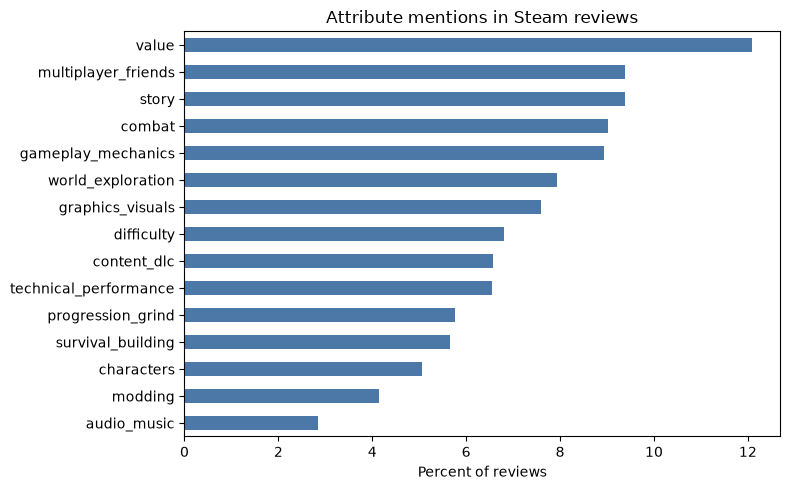

In [22]:
ATTRIBUTE_PATTERNS = {
    'story': r'\b(?:story|storyline|narrative|plot)\b',
    'gameplay_mechanics': r'\b(?:gameplay|mechanics?|controls?)\b',
    'world_exploration': r'\b(?:world|open[ -]?world|map|explor(?:e|es|ed|ing|ation))\b',
    'combat': r'\b(?:combat|fight(?:s|ing)?|battles?|enemies|weapons?|boss(?:es)?)\b',
    'characters': r'\b(?:characters?|protagonists?|npcs?)\b',
    'difficulty': r'\b(?:hard|difficult|difficulty|challenging|challenge|easy)\b',
    'multiplayer_friends': r'\b(?:friends?|multiplayer|co[ -]?op|coop|pvp|online|community)\b',
    'content_dlc': r'\b(?:content|dlc|expansions?|updates?)\b',
    'modding': r'\b(?:mods?|modding|workshop)\b',
    'value': r'\b(?:worth|money|price|priced|buy|bought|purchase[sd]?|sale|free)\b',
    'graphics_visuals': r'\b(?:graphics?|visuals?|beautiful|art[ -]?style|design)\b',
    'survival_building': r'\b(?:survival|building|builds?|base[ -]?building|craft(?:ing|ed)?)\b',
    'technical_performance': r'\b(?:bugs?|buggy|fps|performance|lag|stutter(?:ing)?|crash(?:es|ed|ing)?|optimi[sz](?:e|ed|ation))\b',
    'progression_grind': r'\b(?:levels?|leveling|progress(?:ion)?|grind(?:y|ing|ed)?|upgrades?|skill[ -]?tree)\b',
    'audio_music': r'\b(?:music|soundtrack|audio)\b',
}

review_lower = reviews['review'].str.lower()
mentions = pd.DataFrame({
    attribute: review_lower.str.contains(pattern, regex=True, na=False)
    for attribute, pattern in ATTRIBUTE_PATTERNS.items()
})

attribute_frequency = (
    pd.DataFrame({
        'review_count': mentions.sum(),
        'review_percent': mentions.mean().mul(100),
    })
    .sort_values('review_count', ascending=False)
)
display(attribute_frequency.round(2))

ax = attribute_frequency['review_percent'].sort_values().plot(
    kind='barh', figsize=(8, 5), color='#4C78A8'
)
ax.set(title='Attribute mentions in Steam reviews', xlabel='Percent of reviews', ylabel='')
plt.tight_layout()
plt.show()

### Frequency result and lift analysis

The frequency results show that **value** is discussed most often (906 reviews; 12.08%). It is followed by **multiplayer/friends** (704; 9.39%), **story** (703; 9.37%), **combat** (677; 9.03%), and **gameplay/mechanics** (670; 8.93%). Audio/music is the least frequent selected attribute (213; 2.84%), so conclusions involving it need more caution.

The next cell checks which attributes are mentioned together unusually often. For attributes A and B, lift is: $Lift(A,B)=P(A\cap B)/(P(A)P(B))$. A lift above 1 means the pair appears together more often than expected if the attributes were independent; below 1 means less often. Joint counts are shown alongside lift, and only pairs found together in at least 50 reviews are listed.

,attribute_a,attribute_b,joint_reviews,lift
98,graphics_visuals,audio_music,105.0,6.49
104,progression_grind,audio_music,65.0,5.30
26,gameplay_mechanics,audio_music,100.0,5.26
59,characters,audio_music,55.0,5.10
100,survival_building,progression_grind,117.0,4.79
39,combat,characters,158.0,4.61
68,difficulty,audio_music,66.0,4.56
67,difficulty,progression_grind,133.0,4.53
22,gameplay_mechanics,graphics_visuals,230.0,4.52
56,characters,survival_building,97.0,4.52


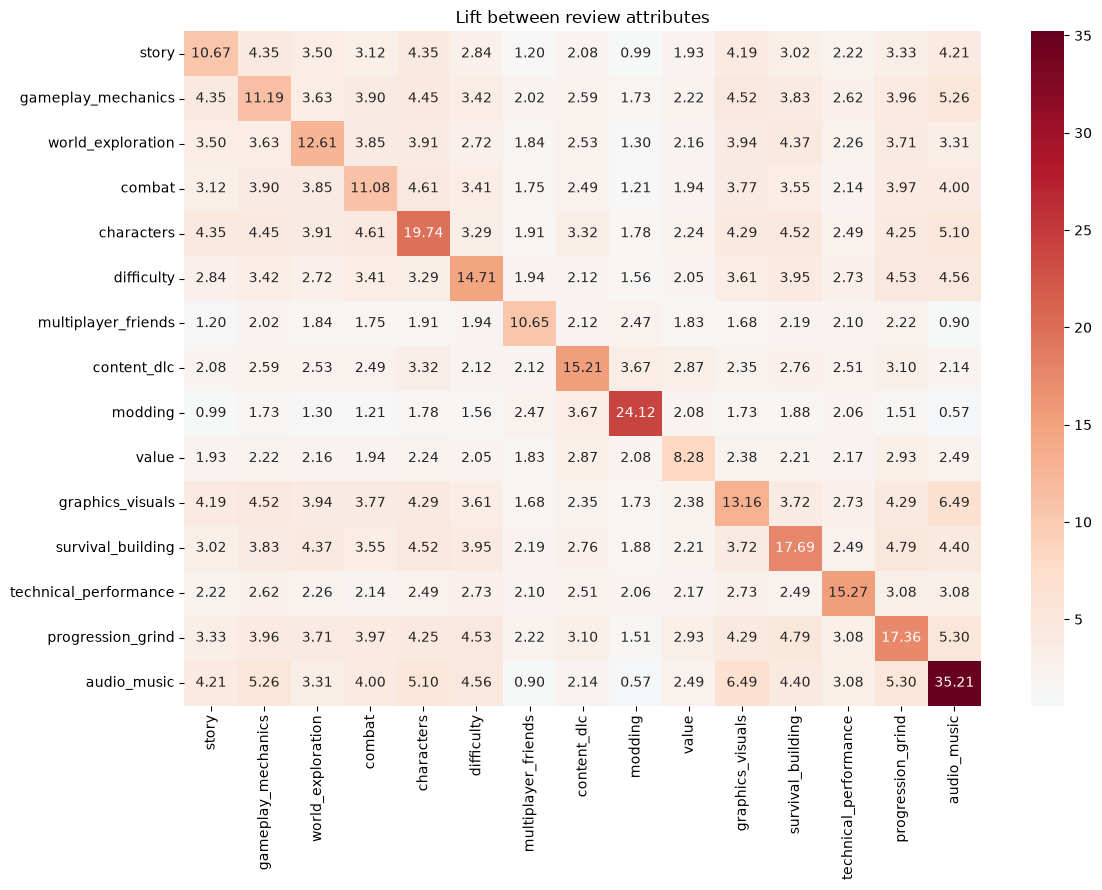

In [23]:
selected_attributes = [
    'story', 'gameplay_mechanics', 'world_exploration', 'combat', 'characters',
    'difficulty', 'multiplayer_friends', 'content_dlc', 'modding', 'value',
    'graphics_visuals', 'survival_building', 'technical_performance',
    'progression_grind', 'audio_music',
]
selected_mentions = mentions[selected_attributes].astype(int)
marginal_probability = selected_mentions.mean()

lift = pd.DataFrame(index=selected_attributes, columns=selected_attributes, dtype=float)
joint_counts = pd.DataFrame(index=selected_attributes, columns=selected_attributes, dtype=int)

for attribute_a in selected_attributes:
    for attribute_b in selected_attributes:
        joint = (selected_mentions[attribute_a] & selected_mentions[attribute_b])
        joint_counts.loc[attribute_a, attribute_b] = int(joint.sum())
        denominator = marginal_probability[attribute_a] * marginal_probability[attribute_b]
        lift.loc[attribute_a, attribute_b] = joint.mean() / denominator if denominator else np.nan

pair_rows = []
for i, attribute_a in enumerate(selected_attributes):
    for attribute_b in selected_attributes[i + 1:]:
        pair_rows.append({
            'attribute_a': attribute_a,
            'attribute_b': attribute_b,
            'joint_reviews': joint_counts.loc[attribute_a, attribute_b],
            'lift': lift.loc[attribute_a, attribute_b],
        })

MIN_JOINT_REVIEWS = 50
lift_pairs = (
    pd.DataFrame(pair_rows)
    .query('joint_reviews >= @MIN_JOINT_REVIEWS')
    .sort_values(['lift', 'joint_reviews'], ascending=False)
)
display(lift_pairs.head(15).round(2))

plt.figure(figsize=(12, 9))
sns.heatmap(lift.astype(float), annot=True, fmt='.2f', cmap='RdBu_r', center=1)
plt.title('Lift between review attributes')
plt.tight_layout()
plt.show()

### Task B interpretation

The strongest reliable off-diagonal pair is **graphics/visuals + audio/music** (lift 6.49, 105 co-mentions), suggesting that reviews discussing presentation often evaluate both visual and sound design. Other strong pairs are **progression/grind + audio/music** (5.30, 65), **gameplay/mechanics + audio/music** (5.26, 100), and **characters + audio/music** (5.10, 55). These audio-related lifts are interesting but should be treated cautiously because audio/music appears in only 213 reviews. More broadly supported relationships include **survival/building + progression/grind** (4.79, 117), **combat + characters** (4.61, 158), and **gameplay/mechanics + graphics/visuals** (4.52, 230). **Story + gameplay/mechanics** combines a strong lift of 4.35 with 273 joint reviews, the largest joint count among the displayed pairs, making it one of the most dependable relationships in the corpus.

This analysis informs the recommender in two ways: it confirms which user preferences are represented in the corpus, and it warns us when a requested combination is rare. Lift describes co-mention, not whether the reviewer liked either attribute, so sentiment is still needed for ranking.

# Task C — Recommender 1: Bag-of-Words + cosine similarity

The user's full natural-language request is treated as a single document, exactly as the review text is. Ordinary preprocessing (lowercasing, punctuation removal, stopword removal) is applied to both, and a bag-of-words vector is built directly from the processed request — no separate attribute list is extracted first; that structured interpretation is left for Task F. Cosine similarity between the query vector and each review's BoW vector measures how closely the review's language matches the request. Because a closely-matching review can still be a negative one, VADER sentiment is layered on top so that similarity alone does not drive the recommendation. The same natural-language request used in Task E is reused here so that the BoW, pretrained, custom-embedding, and LLM-guided systems can be compared fairly.

In [24]:
# Task C relies only on the 'reviews' DataFrame produced in Task B
# (one row per usable review, with an appid, a game name, and review text).
from sklearn.feature_extraction.text import CountVectorizer

USER_REQUEST = (
    "I'm looking for a game with a really immersive world and a strong story. "
    "I enjoy exploration and challenging combat, but I don't want something "
    "that feels repetitive or grindy."
)

# Keep negation words so that phrases such as "don't want" are not reduced to
# "want" once stopwords are removed.
BOW_STOP_WORDS = set(ENGLISH_STOP_WORDS) - {'no', 'not', 'nor', 'without'}


def bow_preprocess(text: str) -> str:
    """Ordinary preprocessing for BoW: lowercase, strip punctuation/digits,
    drop stopwords, and drop single-character tokens."""
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
    kept = [word for word in words if word not in BOW_STOP_WORDS and len(word) > 1]
    return ' '.join(kept)


reviews['bow_text'] = reviews['review'].map(bow_preprocess)
query_text = bow_preprocess(USER_REQUEST)

# The vocabulary is learned from the review corpus only; the user's request is
# then projected onto that same vocabulary (words the corpus never uses cannot
# contribute to similarity either way).
count_vectorizer = CountVectorizer(min_df=3)
review_bow_matrix = count_vectorizer.fit_transform(reviews['bow_text'])
query_bow_vector = count_vectorizer.transform([query_text])

reviews['bow_similarity'] = cosine_similarity(review_bow_matrix, query_bow_vector).ravel()

print(USER_REQUEST)
print(f'BoW vocabulary size: {len(count_vectorizer.vocabulary_):,}')
display(
    reviews[['game', 'review', 'bow_similarity']]
    .sort_values('bow_similarity', ascending=False)
    .head(5)
)

I'm looking for a game with a really immersive world and a strong story. I enjoy exploration and challenging combat, but I don't want something that feels repetitive or grindy.
BoW vocabulary size: 5,929


,game,review,bow_similarity
1756,NARAKA: BLADEPOINT,great game immersive combat.,0.375000
3714,Assassin's Creed Odyssey,I absolutely loved Assassin’s Creed Odyssey. T...,0.356348
498,Cyberpunk 2077,I don't want to say they really captured the h...,0.353553
6301,SCUM,it is everything I want in a game,0.353553
6042,Far Cry 3,"I greatly enjoy this game, the story is the be...",0.348155


In [25]:
# VADER estimates whether a closely-matching review is actually favorable.
# Task C does not extract a separate list of preference attributes, so sentiment
# is computed once per review (not attribute-by-attribute as in Task F).
import nltk
nltk.download('vader_lexicon', quiet=True)

bow_sentiment_analyzer = SentimentIntensityAnalyzer()
reviews['bow_sentiment_compound'] = reviews['review'].map(
    lambda text: bow_sentiment_analyzer.polarity_scores(text)['compound']
)

# Cosine similarity between non-negative BoW vectors already lies in [0, 1].
# VADER's compound score is rescaled from [-1, 1] onto the same [0, 1] range so
# the two signals sit on a comparable scale before they are combined.
reviews['bow_sentiment_01'] = (reviews['bow_sentiment_compound'] + 1) / 2

# Similarity is weighted more heavily than sentiment: it is what ties the review
# to the user's request, while sentiment only guards against language that
# matches the request but is actually a complaint.
BOW_SIMILARITY_WEIGHT = 0.75
reviews['bow_review_score'] = (
    BOW_SIMILARITY_WEIGHT * reviews['bow_similarity']
    + (1 - BOW_SIMILARITY_WEIGHT) * reviews['bow_sentiment_01']
)

display(
    reviews[['game', 'review', 'bow_similarity', 'bow_sentiment_compound', 'bow_review_score']]
    .sort_values('bow_review_score', ascending=False)
    .head(5)
    .round(3)
)

,game,review,bow_similarity,bow_sentiment_compound,bow_review_score
3714,Assassin's Creed Odyssey,I absolutely loved Assassin’s Creed Odyssey. T...,0.356,0.973,0.514
4130,God of War,I really enjoyed this game from beginning to e...,0.345,0.999,0.509
6042,Far Cry 3,"I greatly enjoy this game, the story is the be...",0.348,0.931,0.503
7256,Poppy Playtime,Really well made game loved it i love the stor...,0.335,0.888,0.488
6581,Don't Starve,Really easy game if you don't starve or don't ...,0.333,0.829,0.479


In [26]:
# Aggregate review-level scores to the game level: for each game, take its ten
# most relevant reviews (by bow_review_score) and average their scores. This
# mirrors the aggregation rule used in Task E so the two methods are comparable,
# and it keeps a single unusually strong or weak review from deciding a game's
# rank on its own.
TOP_RELEVANT_REVIEWS_BOW = 10

top_evidence_bow = (
    reviews.sort_values('bow_review_score', ascending=False)
    .groupby(['appid', 'game'], group_keys=False)
    .head(TOP_RELEVANT_REVIEWS_BOW)
)

bow_game_scores = (
    top_evidence_bow.groupby(['appid', 'game'])
    .agg(
        bow_score=('bow_review_score', 'mean'),
        mean_bow_similarity=('bow_similarity', 'mean'),
        mean_sentiment=('bow_sentiment_compound', 'mean'),
        evidence_reviews=('review_id', 'count'),
    )
    .reset_index()
    .sort_values('bow_score', ascending=False)
    .reset_index(drop=True)
)
bow_game_scores.index = bow_game_scores.index + 1
bow_game_scores.index.name = 'rank'

print('Task C — Top 3 recommendations (Bag-of-Words + cosine similarity)')
display(bow_game_scores.head(3).round(3))

print('Task C — Top 3 recommendations plus the next 20 contenders')
display(bow_game_scores.head(23).round(3))

# Saved so the Task E/F comparison cells (which already look for this exact
# file and column name) can merge the Task C ranking in automatically.
bow_results_path = DATA_DIR / 'task_c_bow_results.csv'
bow_game_scores[['game', 'bow_score']].to_csv(bow_results_path, index=False)
print(f'Saved Task C results to {bow_results_path}')

Task C — Top 3 recommendations (Bag-of-Words + cosine similarity)


,appid,game,bow_score,mean_bow_similarity,mean_sentiment,evidence_reviews
rank,,,,,,
1,1716740,Starfield,0.408,0.219,0.947,10
2,319630,Life is Strange - Episode 1,0.396,0.211,0.905,10
3,812140,Assassin's Creed Odyssey,0.395,0.215,0.870,10


Task C — Top 3 recommendations plus the next 20 contenders


,appid,game,bow_score,mean_bow_similarity,mean_sentiment,evidence_reviews
rank,,,,,,
1,1716740,Starfield,0.408,0.219,0.947,10
2,319630,Life is Strange - Episode 1,0.396,0.211,0.905,10
3,812140,Assassin's Creed Odyssey,0.395,0.215,0.870,10
4,220240,Far Cry 3,0.391,0.203,0.916,10
5,1172380,STAR WARS Jedi: Fallen Order,0.390,0.226,0.762,10
6,391220,Rise of the Tomb Raider,0.389,0.218,0.802,10
7,1593500,God of War,0.386,0.223,0.748,10
8,1259420,Days Gone,0.384,0.194,0.906,10
9,305620,The Long Dark,0.383,0.200,0.863,10


Saved Task C results to data/task_c_bow_results.csv


### Task C discussion

**Preprocessing.** The user's full request and every review are lowercased, stripped of punctuation, and tokenized into words. Standard English stopwords are removed, except for negation terms (`no`, `not`, `nor`, `without`), which are kept so that phrases like "don't want something repetitive" are not flattened into "want ... repetitive." No separate list of preferred attributes is pulled out of the request; the cleaned request is fed directly into the bag-of-words model as one document, per the assignment's instructions for Task C.

**Similarity.** A bag-of-words vocabulary is learned from the review corpus (words appearing in at least 3 reviews), and both the reviews and the query are represented as count vectors over that shared vocabulary. Cosine similarity between the query vector and each review vector measures how much of the request's vocabulary shows up in that review, regardless of review length.

**Sentiment.** Because high lexical overlap can still describe a reviewer's complaint (e.g., a review that matches on "combat" and "repetitive" but means it negatively), VADER's compound sentiment score is computed per review and rescaled to [0, 1]. Task C does not need attribute-specific sentiment, since no separate preference attributes were extracted; one overall sentiment score per review is sufficient here.

**Combining scores.** Each review's final score blends similarity and sentiment as `0.75 × similarity + 0.25 × sentiment`, giving more weight to how closely the review's language matches the request while still penalizing reviews that are negative overall.

**Aggregation.** Multiple reviews describe the same game, so each game's ten highest-scoring reviews are averaged into a single game-level score. Using the top reviews (rather than every review) keeps the score focused on the evidence that is actually relevant to the request, and averaging rather than taking a single max prevents one outlier review from deciding the ranking.

The Bag-of-Words recommender ranked **Starfield**, **Life is Strange - Episode 1**, and **Assassin's Creed Odyssey** as the top three recommendations, with final scores of approximately **0.408, 0.396, and 0.395**, respectively.

The method represents the user's full natural-language request and each review using a count-based Bag-of-Words representation and measures their similarity using cosine similarity. VADER sentiment is then incorporated so that reviews containing vocabulary similar to the user's request are not rewarded equally when the review itself expresses a negative opinion. Review-level scores are aggregated at the game level using the ten highest-scoring reviews for each game.

The results illustrate both the usefulness and limitation of lexical matching. Games can rank highly when their reviews contain words that overlap strongly with the user's requested characteristics, but Bag-of-Words does not directly recognize semantic relationships between different words or phrases. For example, two reviews can describe similar ideas using different vocabulary and receive relatively low similarity. This limitation provides a useful baseline for comparison with the embedding-based approaches in the later tasks.


# Task D — Recommender 2: Pretrained word vectors (spaCy `en_core_web_md`)

Task D repeats the Task C recommendation but changes how words are represented. Task C counted words, so two texts only matched when they shared the same tokens. In Task D, every word is replaced with a 300-dimensional vector from spaCy's medium English model, which was trained on general web text. Words used in similar contexts on the web, such as combat and fighting, receive similar vectors, so a review can match the request without repeating its exact wording.

Everything else from Task C is held constant in Task D.

| Step | Task C (BoW) | Task D (pretrained vectors) |
|---|---|---|
| User request | Full request treated as one document | Same |
| Preprocessing | `bow_preprocess` (lowercase, strip punctuation, drop stopwords except negations) | Same function, same tokens |
| Text representation | Word-count vector over the corpus vocabulary | Mean of the spaCy vectors of the same tokens |
| Similarity | Cosine(query, review) | Cosine(query, review) |
| Sentiment | VADER compound, rescaled to 0–1 | Same VADER scores (reused, not recomputed) |
| Review score | 0.75 × similarity + 0.25 × sentiment | Same weights |
| Product score | Mean of each game's 10 highest-scoring reviews | Same rule |

Because only the representation changes, any difference between the Task C and Task D rankings can be attributed to lexical versus pretrained semantic matching.

### D1. Load the pretrained vectors

The cell below loads `en_core_web_md`. It also prints how the vector table is stored. The medium model maps several hundred thousand vocabulary keys onto only 20,000 distinct vectors, so groups of words share exactly the same vector. We inspect the consequences of that compression in D4.

In [27]:
# Load spaCy and its medium English model (300-dimensional pretrained vectors).
import importlib
import subprocess
import sys

try:
    import spacy
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'spacy'], check=True)
    importlib.invalidate_caches()
    import spacy

try:
    nlp_md = spacy.load('en_core_web_md')
except OSError:
    from spacy.cli import download
    download('en_core_web_md')
    importlib.invalidate_caches()
    try:
        nlp_md = spacy.load('en_core_web_md')
    except OSError as error:
        raise RuntimeError(
            'en_core_web_md was downloaded but cannot be imported yet. '
            'Restart the kernel and run the notebook again.'
        ) from error

ptv_table = nlp_md.vocab.vectors
PTV_DIM = ptv_table.shape[1]
print(f'spaCy version: {spacy.__version__}')
print(f'Vocabulary keys with a vector: {ptv_table.n_keys:,}')
print(f'Distinct vectors (rows):       {ptv_table.shape[0]:,}')
print(f'Vector dimensions:             {PTV_DIM}')

spaCy version: 3.8.16
Vocabulary keys with a vector: 684,830
Distinct vectors (rows):       20,000
Vector dimensions:             300


### D2. Represent the request and the reviews

Both the request and each review are run through the same `bow_preprocess` function used in Task C, so the two methods see identical tokens. Each token is then looked up in the spaCy vocabulary, and the text is represented by the average of its token vectors (repeated words count more than once, mirroring the word counts in BoW). Tokens without a pretrained vector are skipped; a review in which no token has a vector receives a zero vector and therefore a similarity of 0. The first table checks every query token, or whether the Task C vocabulary contains it and whether spaCy has a vector for it. The coverage statistics show how much of the review text the pretrained model can represent.

In [28]:
# Build pretrained-vector representations from same tokens Task C used
_ptv_cache: dict[str, np.ndarray | None] = {}


def ptv_word_vector(word: str) -> np.ndarray | None:
    """Return the spaCy vector for a word, or None if the model has no vector"""
    if word not in _ptv_cache:
        lexeme = nlp_md.vocab[word]
        _ptv_cache[word] = lexeme.vector if lexeme.has_vector else None
    return _ptv_cache[word]


def ptv_text_vector(processed_text: str) -> np.ndarray:
    """Average the pretrained vectors of an already-preprocessed text"""
    vectors = [ptv_word_vector(word) for word in processed_text.split()]
    vectors = [vector for vector in vectors if vector is not None]
    if not vectors:
        return np.zeros(PTV_DIM, dtype=np.float32)
    return np.mean(vectors, axis=0)


# Query: exactly the processed request from Task C.
ptv_query_vector = ptv_text_vector(query_text).reshape(1, -1)
query_token_check = pd.DataFrame(
    [
        {
            'query_token': token,
            'in_task_c_bow_vocabulary': token in count_vectorizer.vocabulary_,
            'has_pretrained_vector': ptv_word_vector(token) is not None,
        }
        for token in query_text.split()
    ]
)
print('Processed request:', query_text)
display(query_token_check)

# Reviews: one 300-dimensional vector per review.
ptv_review_matrix = np.vstack(reviews['bow_text'].map(ptv_text_vector).to_numpy())
reviews['ptv_similarity'] = cosine_similarity(ptv_review_matrix, ptv_query_vector).ravel()

all_review_tokens = [token for text in reviews['bow_text'] for token in text.split()]
token_coverage = np.mean([ptv_word_vector(token) is not None for token in all_review_tokens])
zero_vector_reviews = int((np.linalg.norm(ptv_review_matrix, axis=1) == 0).sum())
print(f'Share of review tokens with a pretrained vector: {token_coverage:.1%}')
print(f'Reviews with no usable tokens (similarity set to 0): {zero_vector_reviews}')

display(
    reviews[['game', 'review', 'bow_similarity', 'ptv_similarity']]
    .sort_values('ptv_similarity', ascending=False)
    .head(5)
    .round(3)
)

Processed request: i'm looking game really immersive world strong story enjoy exploration challenging combat don't want feels repetitive grindy


,query_token,in_task_c_bow_vocabulary,has_pretrained_vector
0,i'm,False,False
1,looking,True,True
2,game,True,True
3,really,True,True
4,immersive,True,True
5,world,True,True
6,strong,True,True
7,story,True,True
8,enjoy,True,True
9,exploration,True,True


Share of review tokens with a pretrained vector: 96.7%
Reviews with no usable tokens (similarity set to 0): 131


,game,review,bow_similarity,ptv_similarity
4633,BioShock Infinite,I enjoyed the gameplay; didn't like the ending...,0.180,0.938
91,Terraria,This game is amazing for people who love adven...,0.164,0.937
3244,Divinity: Original Sin 2 - Definitive Edition,Divinity: Original Sin 2 is a comforting game....,0.249,0.935
7267,Kenshi,[h1] A good game tells a story. A great game l...,0.318,0.935
2675,鬼谷八荒 Tale of Immortal,If you love the Xianxia fantasy world you'll l...,0.188,0.931


### D3. Combine similarity with sentiment and aggregate to games

The scoring rule is copied from Task C so that the comparison isolates the representation. Each review's score is `0.75 × pretrained similarity + 0.25 × VADER sentiment (0–1)`, reusing the VADER scores already computed in Task C. Negative cosine values are clipped to 0 so that the similarity term stays on a 0–1 scale. Each game's score is the mean of its ten highest-scoring reviews, which also matches Task C.

The table shows the three recommendations plus the next 20 contenders. `bow_rank` is the same game's position in Task C, so rank movement is visible directly. The results are saved to `data/task_d_pretrained_results.csv`.

In [29]:
# Same scoring and aggregation rules as Task C, with pretrained similarity swapped in
PTV_SIMILARITY_WEIGHT = BOW_SIMILARITY_WEIGHT          # 0.75, as in Task C
TOP_RELEVANT_REVIEWS_PTV = TOP_RELEVANT_REVIEWS_BOW    # 10, as in Task C

reviews['ptv_review_score'] = (
    PTV_SIMILARITY_WEIGHT * reviews['ptv_similarity'].clip(lower=0)
    + (1 - PTV_SIMILARITY_WEIGHT) * reviews['bow_sentiment_01']
)

top_evidence_ptv = (
    reviews.sort_values('ptv_review_score', ascending=False)
    .groupby(['appid', 'game'], group_keys=False)
    .head(TOP_RELEVANT_REVIEWS_PTV)
)

ptv_game_scores = (
    top_evidence_ptv.groupby(['appid', 'game'])
    .agg(
        ptv_score=('ptv_review_score', 'mean'),
        mean_ptv_similarity=('ptv_similarity', 'mean'),
        mean_sentiment=('bow_sentiment_compound', 'mean'),
        evidence_reviews=('review_id', 'count'),
    )
    .reset_index()
    .sort_values('ptv_score', ascending=False)
    .reset_index(drop=True)
)
ptv_game_scores.index = ptv_game_scores.index + 1
ptv_game_scores.index.name = 'rank'

# Attach each game's Task C rank for direct comparison.
bow_rank_lookup = pd.Series(bow_game_scores.index, index=bow_game_scores['appid'])
ptv_game_scores['bow_rank'] = ptv_game_scores['appid'].map(bow_rank_lookup)

print('Task D — Top 3 recommendations (spaCy pretrained vectors + cosine similarity)')
display(ptv_game_scores.head(3).round(3))

print('Task D — Top 3 recommendations plus the next 20 contenders')
display(ptv_game_scores.head(23).round(3))

ptv_results_path = DATA_DIR / 'task_d_pretrained_results.csv'
ptv_game_scores.to_csv(ptv_results_path)
print(f'Saved Task D results to {ptv_results_path}')

Task D — Top 3 recommendations (spaCy pretrained vectors + cosine similarity)


,appid,game,ptv_score,mean_ptv_similarity,mean_sentiment,evidence_reviews,bow_rank
rank,,,,,,,
1,1716740,Starfield,0.920,0.899,0.965,10,1
2,8870,BioShock Infinite,0.919,0.901,0.953,10,20
3,379430,Kingdom Come: Deliverance,0.914,0.896,0.937,10,10


Task D — Top 3 recommendations plus the next 20 contenders


,appid,game,ptv_score,mean_ptv_similarity,mean_sentiment,evidence_reviews,bow_rank
rank,,,,,,,
1,1716740,Starfield,0.920,0.899,0.965,10,1
2,8870,BioShock Infinite,0.919,0.901,0.953,10,20
3,379430,Kingdom Come: Deliverance,0.914,0.896,0.937,10,10
4,1057090,Ori and the Will of the Wisps,0.913,0.892,0.957,10,44
5,319630,Life is Strange - Episode 1,0.912,0.894,0.938,10,2
6,1145360,Hades,0.911,0.893,0.936,10,23
7,1259420,Days Gone,0.911,0.892,0.936,10,8
8,2054970,Dragon's Dogma 2,0.910,0.890,0.944,10,14
9,275850,No Man's Sky,0.909,0.887,0.950,10,13


Saved Task D results to data/task_d_pretrained_results.csv


### D4. Diagnostics: do semantic relationships help?

Here we look at what the pretrained vectors actually believe about the words in our request. The next cell answers three questions using only the spaCy model, so its results do not depend on the review sample:

1. **Word pairs:** are useful paraphrases close (e.g. *combat* / *fights*, *story* / *narrative*)? Are opposites or off-topic senses also close (e.g. *challenging* / *easy*, *exploration* / *oil*)?
2. **Phrases:** using the same averaging as the recommender, does *challenging combat* match *difficult fights*? Does it also match *easy combat*, which the user did not ask for?
3. **Shared vectors:** because `en_core_web_md` stores only 20,000 distinct vectors, many words are mapped onto the same row. For each important query word, the table lists other words from our review vocabulary that share its vector exactly. These words are indistinguishable from the query word to Task D.

In [30]:
def ptv_cosine(text_a: str, text_b: str) -> float:
    vector_a = ptv_text_vector(bow_preprocess(text_a))
    vector_b = ptv_text_vector(bow_preprocess(text_b))
    norm = np.linalg.norm(vector_a) * np.linalg.norm(vector_b)
    return float(vector_a @ vector_b / norm) if norm else np.nan


def ptv_vector_id(word: str) -> bytes | None:
    """Fingerprint of a word's vector; equal fingerprints mean identical vectors"""
    vector = ptv_word_vector(word)
    return None if vector is None else vector.tobytes()


word_pairs = [
    # Useful paraphrases the user would accept
    ('combat', 'fights', 'paraphrase'), ('combat', 'battles', 'paraphrase'),
    ('challenging', 'difficult', 'paraphrase'), ('story', 'narrative', 'paraphrase'),
    ('story', 'plot', 'paraphrase'), ('repetitive', 'tedious', 'paraphrase'),
    # Pairs the user would NOT treat as equivalent
    ('challenging', 'easy', 'opposite'), ('strong', 'weak', 'opposite'),
    ('challenging', 'great', 'generic praise'), ('challenging', 'beautiful', 'generic praise'),
    ('repetitive', 'varied', 'opposite'), ('story', 'gameplay', 'different attribute'),
    ('immersive', 'interactive', 'different attribute'),
    ('exploration', 'exploitation', 'off-topic sense'), ('exploration', 'oil', 'off-topic sense'),
    ('world', 'country', 'off-topic sense'), ('combat', 'military', 'off-topic sense'),
    ('grindy', 'grind', 'should be close'),
]
word_pair_table = pd.DataFrame(
    [
        {
            'word_a': a, 'word_b': b, 'relationship': relation,
            'cosine': ptv_cosine(a, b),
            'identical_vector': ptv_vector_id(a) is not None and ptv_vector_id(a) == ptv_vector_id(b),
        }
        for a, b, relation in word_pairs
    ]
)
print('Word-level similarity in en_core_web_md')
display(word_pair_table.round(3))

phrase_pairs = [
    ('challenging combat', 'difficult fights', 'paraphrase (wanted)'),
    ('challenging combat', 'tough boss fights', 'paraphrase (wanted)'),
    ('challenging combat', 'easy combat', 'opposite (not wanted)'),
    ('challenging combat', 'boring combat', 'negative (not wanted)'),
    ('challenging combat', 'beautiful graphics', 'different attribute'),
    ('strong story', 'compelling narrative', 'paraphrase (wanted)'),
    ('strong story', 'weak story', 'opposite (not wanted)'),
    ('immersive world', 'atmospheric open world', 'paraphrase (wanted)'),
    ('repetitive grindy', 'tedious grind', 'paraphrase of the avoidance'),
    ('repetitive grindy', 'varied and fresh', 'opposite of the avoidance'),
]
phrase_table = pd.DataFrame(
    [
        {'phrase_a': a, 'phrase_b': b, 'relationship': relation, 'cosine': ptv_cosine(a, b)}
        for a, b, relation in phrase_pairs
    ]
)
print('Phrase-level similarity (same averaging as the recommender)')
display(phrase_table.round(3))

# Which words from our own review vocabulary share each query word's vector?
vector_members: dict[bytes, set[str]] = {}
for word in count_vectorizer.vocabulary_:
    fingerprint = ptv_vector_id(word)
    if fingerprint is not None:
        vector_members.setdefault(fingerprint, set()).add(word)

shared_rows = []
for word in ['challenging', 'difficult', 'easy', 'combat', 'story', 'immersive',
             'repetitive', 'grindy', 'exploration', 'world', 'strong']:
    members = sorted(vector_members.get(ptv_vector_id(word), set()) - {word})
    shared_rows.append({
        'query_word': word,
        'corpus_words_with_identical_vector': len(members),
        'examples': ', '.join(members[:20]),
    })
print('Review-vocabulary words that share the exact same pretrained vector')
display(pd.DataFrame(shared_rows))

Word-level similarity in en_core_web_md


,word_a,word_b,relationship,cosine,identical_vector
0,combat,fights,paraphrase,0.781,False
1,combat,battles,paraphrase,1.000,True
2,challenging,difficult,paraphrase,1.000,True
3,story,narrative,paraphrase,1.000,True
4,story,plot,paraphrase,1.000,True
5,repetitive,tedious,paraphrase,1.000,True
6,challenging,easy,opposite,1.000,True
7,strong,weak,opposite,0.643,False
8,challenging,great,generic praise,1.000,True
9,challenging,beautiful,generic praise,1.000,True


Phrase-level similarity (same averaging as the recommender)


,phrase_a,phrase_b,relationship,cosine
0,challenging combat,difficult fights,paraphrase (wanted),0.902
1,challenging combat,tough boss fights,paraphrase (wanted),0.680
2,challenging combat,easy combat,opposite (not wanted),1.000
3,challenging combat,boring combat,negative (not wanted),0.774
4,challenging combat,beautiful graphics,different attribute,0.537
5,strong story,compelling narrative,paraphrase (wanted),0.785
6,strong story,weak story,opposite (not wanted),0.869
7,immersive world,atmospheric open world,paraphrase (wanted),0.573
8,repetitive grindy,tedious grind,paraphrase of the avoidance,0.705
9,repetitive grindy,varied and fresh,opposite of the avoidance,0.226


Review-vocabulary words that share the exact same pretrained vector


,query_word,corpus_words_with_identical_vector,examples
0,challenging,76,"absolutely, amazingly, appealing, attractive, ..."
1,difficult,76,"absolutely, amazingly, appealing, attractive, ..."
2,easy,76,"absolutely, amazingly, appealing, attractive, ..."
3,combat,13,"action, army, battles, camp, defeating, faced,..."
4,story,33,"adventure, cinematics, cutscene, cutscenes, en..."
5,immersive,2,"interactive, maps"
6,repetitive,13,"jarring, loops, monotonous, pacing, repeat, re..."
7,grindy,3,"completionist, nitpicks, unfun"
8,exploration,0,
9,world,31,"brotherhood, conscience, depths, destiny, divi..."


### D5. Semantic-only matches in our reviews

This cell shows what happens in the reviews, listing the ones that pretrained vectors rank most highly even though they share no words at all with the request (BoW similarity = 0).

In [31]:
print('Strongest semantic-only matches (no shared words with the request, BoW similarity = 0):')
semantic_only = (
    reviews.loc[reviews['bow_similarity'] == 0,
                ['game', 'review', 'ptv_similarity', 'bow_sentiment_compound']]
    .sort_values('ptv_similarity', ascending=False)
    .head(8)
    .assign(review=lambda frame: frame['review'].str.slice(0, 180))
)
with pd.option_context('display.max_colwidth', 180):
    display(semantic_only.round(3))

Strongest semantic-only matches (no shared words with the request, BoW similarity = 0):


,game,review,ptv_similarity,bow_sentiment_compound
6481,Last Epoch,"Super awesome; love the build diversity and classes' ""feel""! Wish the seasons were a little bit longer but that's probably just me.",0.895,0.829
3473,Portal,"Had a blast. Made me feel incredibly brilliant when I figured out how to solve a puzzle. Even as not a very big fan of puzzles, it is safe to say I had fun with them. I'd say i...",0.891,0.982
5498,Total War: WARHAMMER II,"AI breaking down in sieges constantly sucks. You have to siege a lot. Fun, but holy crap babysitting dementia ridden troops is not fun. I hate finding an amnesiatic group on a ...",0.891,-0.608
3044,DOOM Eternal,Must play even if u dont play shooter games . Makes u feel unstoppable and gr8est. Would recommend keyboard and mouse. There's nothing like DOOM Series. It's unique and 1 of it...,0.888,0.919
6859,Cult of the Lamb,"Initially shrugged this off as another roguelike that wasn't worth my time, but co-op convinced me to give it a shot. The interplay between dungeon crawling and cult management...",0.883,0.922
1539,Sid Meier’s Civilization VI,"not nice, like a simple hard simulation. i did not like it.",0.882,-0.714
978,Valheim,One of the best games of all time. Why can't my life be like Valheim...,0.882,0.772
3126,Z1 Battle Royale,One of the best battle royale games of all time. I made so many life long friends in this community. It's a shame it didn't last. 10/10,0.881,0.382


### D6. Compare the Task D ranking with Task C

The next cell shows the two rankings for all 250 games. It reports how many games the two methods share in their top 3, 10, and 23, and then the Spearman rank correlation between the two complete rankings. The table lists every game that appears in either method's top 10, with its rank under each method. It also prints the two strongest pieces of evidence (highest-scoring reviews) for each Task D top-three game so we can see how real the match is.

In [32]:
comparison_cd = (
    bow_game_scores.reset_index()[['appid', 'game', 'rank', 'bow_score', 'mean_bow_similarity']]
    .rename(columns={'rank': 'bow_rank'})
    .merge(
        ptv_game_scores.reset_index()[['appid', 'rank', 'ptv_score', 'mean_ptv_similarity', 'mean_sentiment']]
        .rename(columns={'rank': 'ptv_rank'}),
        on='appid',
    )
)
comparison_cd['rank_change_c_to_d'] = comparison_cd['bow_rank'] - comparison_cd['ptv_rank']

overlap_summary = pd.Series({
    f'shared games in top {k}': len(
        set(comparison_cd.loc[comparison_cd['bow_rank'] <= k, 'appid'])
        & set(comparison_cd.loc[comparison_cd['ptv_rank'] <= k, 'appid'])
    )
    for k in (3, 10, 23)
})
overlap_summary['Spearman rank correlation (all 250 games)'] = comparison_cd['bow_rank'].corr(
    comparison_cd['ptv_rank'], method='spearman'
)
display(overlap_summary.to_frame('value').round(3))

print('Games in the top 10 of either method:')
display(
    comparison_cd.loc[(comparison_cd['bow_rank'] <= 10) | (comparison_cd['ptv_rank'] <= 10)]
    .sort_values('ptv_rank')
    .round(3)
)

print('Top evidence behind the Task D top three:')
for appid, game in ptv_game_scores.head(3)[['appid', 'game']].itertuples(index=False):
    print(f'\n=== {game} ===')
    evidence = (
        top_evidence_ptv.loc[top_evidence_ptv['appid'] == appid]
        .sort_values('ptv_review_score', ascending=False)
        .head(2)
    )
    for row in evidence.itertuples():
        print(
            f'  [ptv_sim={row.ptv_similarity:.3f}, bow_sim={row.bow_similarity:.3f}, '
            f'sentiment={row.bow_sentiment_compound:.2f}] {row.review[:220]}'
        )

,value
shared games in top 3,1.000
shared games in top 10,5.000
shared games in top 23,13.000
Spearman rank correlation (all 250 games),0.781


Games in the top 10 of either method:


,appid,game,bow_rank,bow_score,mean_bow_similarity,ptv_rank,ptv_score,mean_ptv_similarity,mean_sentiment,rank_change_c_to_d
0,1716740,Starfield,1,0.408,0.219,1,0.920,0.899,0.965,0
19,8870,BioShock Infinite,20,0.378,0.191,2,0.919,0.901,0.953,18
9,379430,Kingdom Come: Deliverance,10,0.382,0.191,3,0.914,0.896,0.937,7
43,1057090,Ori and the Will of the Wisps,44,0.358,0.158,4,0.913,0.892,0.957,40
1,319630,Life is Strange - Episode 1,2,0.396,0.211,5,0.912,0.894,0.938,-3
22,1145360,Hades,23,0.375,0.188,6,0.911,0.893,0.936,17
7,1259420,Days Gone,8,0.384,0.194,7,0.911,0.892,0.936,1
13,2054970,Dragon's Dogma 2,14,0.381,0.191,8,0.910,0.890,0.944,6
12,275850,No Man's Sky,13,0.381,0.187,9,0.909,0.887,0.950,4
8,305620,The Long Dark,9,0.383,0.200,10,0.909,0.891,0.922,-1


Top evidence behind the Task D top three:

=== Starfield ===
  [ptv_sim=0.916, bow_sim=0.220, sentiment=1.00] Starfield is one of those games I will defend despite fully understanding why some people criticize it. I know the reviews are mixed. I know people have criticized the exploration, loading screens, repetitive locations, 
  [ptv_sim=0.923, bow_sim=0.252, sentiment=0.95] It's a game that gets in the way of itself and makes for a frustrating experience. I'm trying to like it, I really am, but every NPC interaction feels stilted and awkward. The plot writing is dull and occasionally feels 

=== BioShock Infinite ===
  [ptv_sim=0.938, bow_sim=0.180, sentiment=0.93] I enjoyed the gameplay; didn't like the ending at all. To be honest, it almost entirely ruins my desire to play the game a second time: great discussions can be had of it, but it feels super pretentious. Fair warning: st
  [ptv_sim=0.913, bow_sim=0.125, sentiment=0.99] The third instalment in the series doesn’t send us do

### D7. Results summary (generated from the outputs above)

In [33]:
from IPython.display import Markdown


def describe_shift(value: float) -> str:
    if value > 0.02:
        return f'rose by {value:.3f}'
    if value < -0.02:
        return f'fell by {abs(value):.3f}'
    return f'barely moved ({value:+.3f})'


c_top3 = list(bow_game_scores['game'].head(3))
d_top3_text = ', '.join(
    f'**{row.game}** ({row.ptv_score:.3f}; Task C rank {int(row.bow_rank)})'
    for row in ptv_game_scores.head(3).itertuples()
)
c_top3_text = ', '.join(f'**{game}**' for game in c_top3)
shared_top3 = int(overlap_summary['shared games in top 3'])
shared_top10 = int(overlap_summary['shared games in top 10'])
shared_top23 = int(overlap_summary['shared games in top 23'])
spearman_rho = overlap_summary['Spearman rank correlation (all 250 games)']

bow_p10, bow_p90 = reviews['bow_similarity'].quantile([0.1, 0.9])
ptv_p10, ptv_p90 = reviews['ptv_similarity'].quantile([0.1, 0.9])
ptv_gap = ptv_game_scores['ptv_score'].iloc[0] - ptv_game_scores['ptv_score'].iloc[22]
bow_gap = bow_game_scores['bow_score'].iloc[0] - bow_game_scores['bow_score'].iloc[22]

top_decile = reviews['ptv_similarity'] >= reviews['ptv_similarity'].quantile(0.9)
semantic_only_share = (reviews.loc[top_decile, 'bow_similarity'] == 0).mean()

biggest_riser = (
    comparison_cd.loc[comparison_cd['ptv_rank'] <= 10]
    .sort_values('rank_change_c_to_d', ascending=False).iloc[0]
)
biggest_faller = (
    comparison_cd.loc[comparison_cd['bow_rank'] <= 10]
    .sort_values('rank_change_c_to_d').iloc[0]
)

summary_md = (
    f'**Recommendations.** Task D recommends {d_top3_text}. '
    f'Task C recommended {c_top3_text}. '
    f'The two methods share {shared_top3} of 3 games in the top 3, {shared_top10} of 10 in the top 10, '
    f'and {shared_top23} of 23 in the top 23. The Spearman rank correlation across all 250 games is '
    f'{spearman_rho:.3f}. The largest climber into the Task D top 10 is **{biggest_riser["game"]}** '
    f'(Task C rank {int(biggest_riser["bow_rank"])} → Task D rank {int(biggest_riser["ptv_rank"])}), '
    f'and the largest faller from the Task C top 10 is **{biggest_faller["game"]}** '
    f'(rank {int(biggest_faller["bow_rank"])} → {int(biggest_faller["ptv_rank"])}).\n\n'
    f'**Semantic-only matching.** {semantic_only_share:.1%} of the reviews in the top 10% of pretrained '
    f'similarity share no words at all with the request (BoW similarity = 0).\n\n'
    f'**Score compression.** The middle 80% of pretrained similarities lies between {ptv_p10:.3f} and '
    f'{ptv_p90:.3f}, versus {bow_p10:.3f} to {bow_p90:.3f} for BoW. The gap between the #1 and #23 games '
    f'is {ptv_gap:.3f} in Task D versus {bow_gap:.3f} in Task C.'
)
display(Markdown(summary_md))

**Recommendations.** Task D recommends **Starfield** (0.920; Task C rank 1), **BioShock Infinite** (0.919; Task C rank 20), **Kingdom Come: Deliverance** (0.914; Task C rank 10). Task C recommended **Starfield**, **Life is Strange - Episode 1**, **Assassin's Creed Odyssey**. The two methods share 1 of 3 games in the top 3, 5 of 10 in the top 10, and 13 of 23 in the top 23. The Spearman rank correlation across all 250 games is 0.781. The largest climber into the Task D top 10 is **Ori and the Will of the Wisps** (Task C rank 44 → Task D rank 4), and the largest faller from the Task C top 10 is **Rise of the Tomb Raider** (rank 6 → 89).

**Semantic-only matching.** 1.2% of the reviews in the top 10% of pretrained similarity share no words at all with the request (BoW similarity = 0).

**Score compression.** The middle 80% of pretrained similarities lies between 0.526 and 0.881, versus 0.000 to 0.177 for BoW. The gap between the #1 and #23 games is 0.023 in Task D versus 0.032 in Task C.

### **Task D discussion**

**Representation.** The request is preprocessed exactly as in Task C and becomes one 300-dimensional vector: the average of the spaCy `en_core_web_md` vectors of its tokens. Every review is represented the same way, and each game by the mean score of its ten best-matching reviews. Only the word representation differs from Task C, and the recommendations and overlap statistics are reported in D7 above.

**Where semantic relationships help.** Pretrained vectors capture paraphrases that BoW cannot. *Combat* and *battles* share a vector, *combat* and *fights* are close (0.78), and *story*, *plot*, and *narrative* are identical. At the phrase level, *challenging combat* and *difficult fights* score 0.90 despite sharing no words, so a review about difficult fights gets zero credit from BoW but substantial credit here. The D5 semantic-only matches show what this looks like in our reviews.

**Where they introduce unhelpful similarity.** The D4 diagnostics reveal important problems for this request:

- **Opposites and generic praise collapse together:** the medium model maps about 685,000 vocabulary keys onto 20,000 vectors, so *challenging*, *difficult*, and *easy* share one vector with roughly 90 other words, including *great* and *beautiful*. *Challenging combat* vs *easy combat* scores 1.00, higher than the genuine paraphrase.
- **Distinct attributes merge:** *Story* shares a vector with *gameplay*, and *immersive* with *interactive*.
- **General-web senses intrude:** *Exploration* shares a vector with *exploitation* and is closer to *oil* (0.36) than to *explore* (0.30).
- **The avoidance clause becomes a positive signal:** Averaging puts *repetitive* and *grindy* into the query as if they were wanted, and *grindy* is barely related to *grind* (0.13), so its gaming meaning is lost.
- **Scores are compressed:** Averaging pulls nearly every review toward a generic "positive game review" direction, so pretrained cosines occupy a much narrower band than BoW cosines (D7). Small differences in wording or sentiment can therefore reorder games.

**Comparison with the BoW recommendations.** The D6 table shows how the rankings differ. Games rise under Task D when their reviews use related but non-identical vocabulary, but also when they contain generic praise or difficulty adjectives that the model cannot distinguish from *challenging*. A high pretrained similarity therefore does not by itself mean that a review discusses story, exploration, or challenging combat.

**Which method gives better recommendations for this request?** BoW gives the more defensible recommendations. Pretrained vectors add value for paraphrases, but they cannot separate *challenging* from *easy*, *story* from *gameplay*, or gaming exploration from mineral exploration, which are exactly the distinctions this user cares about. BoW is more blunt but it gives credit when a review uses the user's own words, so every ranking can be explained word for word. Neither method handles the avoidance clause, which motivates domain-specific vectors (Task E) and explicit preference directions from an LLM intent layer (Task F).

# Task E — Recommender 3: custom word embeddings

A Word2Vec model is trained only on the 7,500 collected Steam reviews. Skip-gram is used because it generally represents less frequent domain words better than CBOW. The model uses 100 dimensions, a context window of 5, a minimum count of 3, and 30 epochs. These are moderate settings for a corpus of this size.

Reviews and query clauses are represented by IDF-weighted averages of their in-vocabulary Word2Vec vectors. IDF is learned from this review corpus, so informative words receive more influence without manually ranking story, exploration, combat, or other preferences. A small rule-based step separates an explicit avoidance clause such as `I don't want ...`; its penalty weight is determined by that clause's share of the query's total IDF mass. VADER overall sentiment then modifies the semantic score. Finally, all 30 reviews are averaged for every game, giving each title the same amount of evidence.

In [13]:
# Keep negation words, although plain Word2Vec still has limited ability to model negation.
STOP_WORDS = set(ENGLISH_STOP_WORDS) - {'no', 'not', 'nor', 'without'}

def tokenize(text: str) -> list[str]:
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
    return [token for token in tokens if token not in STOP_WORDS and len(token) > 1]


reviews['tokens'] = reviews['review'].map(tokenize)
sentences = reviews.loc[reviews['tokens'].str.len() > 0, 'tokens'].tolist()

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    negative=10,
    epochs=30,
    workers=1,
    seed=RANDOM_SEED,
)
print(f'Vocabulary size: {len(w2v_model.wv):,}')

Vocabulary size: 6,318


### Inspect the learned word relationships

The vocabulary size printed above is the number of words that occurred often enough to receive a vector. A larger vocabulary is not automatically better: very rare words would have unreliable vectors in a corpus of this size. The next cell checks a few meaningful neighborhoods before using the model for recommendations. If nearby words make sense within gaming language—for example, multiplayer terms near `coop` or technical terms near `lag`—that is evidence that the custom model learned useful domain context.

In [14]:
# Inspect meaningful neighborhoods before viewing recommendations.
neighborhood_words = [
    'coop', 'multiplayer', 'lag', 'performance',
    'grind', 'progression', 'story', 'exploration',
]

neighborhood_rows = []
for word in neighborhood_words:
    if word in w2v_model.wv:
        for neighbor, similarity in w2v_model.wv.most_similar(word, topn=5):
            neighborhood_rows.append({
                'word': word, 'neighbor': neighbor, 'similarity': similarity
            })
    else:
        neighborhood_rows.append({'word': word, 'neighbor': '[out of vocabulary]', 'similarity': np.nan})

neighborhoods = pd.DataFrame(neighborhood_rows)
display(neighborhoods.round(3))

,word,neighbor,similarity
0,coop,couch,0.601
1,coop,local,0.588
2,coop,swat,0.563
3,coop,mate,0.545
4,coop,toxicity,0.530
5,multiplayer,host,0.575
6,multiplayer,singleplayer,0.569
7,multiplayer,goof,0.556
8,multiplayer,scps,0.535
9,multiplayer,mp,0.532


### Turn the request into product scores

The model learned several useful gaming relationships. `coop` is close to *couch*, *local*, and *mate*, while `multiplayer` is close to *host*, *singleplayer*, and *mp*. `performance` is near *optimisation*, *port*, and *improvements*, and `lag` is near *unstable* and *unbearable*. Progression and grind also have reasonable neighbors such as *boosts*, *raids*, *leaderboards*, *ranks*, and *equip*. Some relationships are noisy: `story` includes game-specific names and a misspelling, while `exploration` includes *Factorio* and *Greece*. This mixture is expected from a relatively small, product-specific corpus and is useful evidence that the vectors capture domain language without being uniformly reliable.

The cell below performs the actual recommendation. It separates the positive request from the explicit avoidance clause, gives each word an IDF weight learned from the corpus, and averages its word vectors. For tokens $t$, the text vector is $v(d)=\sum_t IDF(t)v_t/\sum_t IDF(t)$.

The avoidance weight is the negative clause's share of the request's total IDF mass. Each review receives $Semantic=PositiveSimilarity-w_{negative}\times max(NegativeSimilarity,0)$. That semantic score is scaled to 0–1 and multiplied by VADER sentiment scaled to 0–1: $ReviewScore=Semantic_{0-1}\times Sentiment_{0-1}$. The game score is the mean review score across all 30 reviews. The cell prints 23 contenders, the required top three, and one additional model recommendation.

In [16]:
USER_REQUEST = (
    "I'm looking for a game with a really immersive world and a strong story. "
    "I enjoy exploration and challenging combat, but I don't want something "
    "that feels repetitive or grindy."
)

def split_avoidance_clause(request: str) -> tuple[str, str]:
    # This is a narrow rule for explicit avoidance language, not full intent extraction.
    pattern = re.compile(
        r"\b(?:but\s+)?(?:i\s+)?(?:do\s+not|don't|dont)\s+want\b|\b(?:avoid|without)\b",
        flags=re.IGNORECASE,
    )
    match = pattern.search(request)
    if not match:
        return request, ''
    return request[:match.start()].strip(' ,.'), request[match.end():].strip(' ,.')


# Learn word importance from document frequency in this review corpus.
idf_model = TfidfVectorizer(
    analyzer=lambda tokens: tokens,
    lowercase=False,
    token_pattern=None,
    min_df=3,
)
idf_model.fit(reviews['tokens'])
idf_weights = dict(zip(idf_model.get_feature_names_out(), idf_model.idf_))

def idf_mass(tokens: list[str]) -> float:
    return sum(idf_weights[token] for token in tokens if token in w2v_model.wv and token in idf_weights)


def idf_weighted_embedding(tokens: list[str], model: Word2Vec) -> np.ndarray:
    usable = [token for token in tokens if token in model.wv and token in idf_weights]
    if not usable:
        return np.zeros(model.vector_size, dtype=float)
    weights = np.array([idf_weights[token] for token in usable], dtype=float)
    vectors = np.vstack([model.wv[token] for token in usable])
    return np.average(vectors, axis=0, weights=weights)


positive_clause, negative_clause = split_avoidance_clause(USER_REQUEST)
positive_tokens = tokenize(positive_clause)
negative_tokens = tokenize(negative_clause)
positive_vector = idf_weighted_embedding(positive_tokens, w2v_model).reshape(1, -1)
negative_vector = idf_weighted_embedding(negative_tokens, w2v_model).reshape(1, -1)
review_matrix = np.vstack(
    reviews['tokens'].map(lambda tokens: idf_weighted_embedding(tokens, w2v_model))
)

if not np.any(positive_vector):
    raise ValueError('None of the positive query words are in the custom vocabulary.')

reviews['positive_similarity'] = cosine_similarity(review_matrix, positive_vector).ravel()
if np.any(negative_vector):
    reviews['negative_similarity'] = cosine_similarity(review_matrix, negative_vector).ravel()
else:
    reviews['negative_similarity'] = 0.0

positive_mass = idf_mass(positive_tokens)
negative_mass = idf_mass(negative_tokens)
total_query_mass = positive_mass + negative_mass
negative_clause_weight = negative_mass / total_query_mass if total_query_mass else 0.0

# Penalize semantic similarity to the avoidance clause. Negative cosine values
# are clipped because being dissimilar should not create an extra reward.
reviews['avoidance_penalty'] = negative_clause_weight * reviews['negative_similarity'].clip(lower=0)
reviews['semantic_score_raw'] = reviews['positive_similarity'] - reviews['avoidance_penalty']

# VADER measures whether the matching review is favorable overall.
# The first run may download the small VADER lexicon if it is not installed.
import nltk
nltk.download('vader_lexicon', quiet=True)
sentiment_analyzer = SentimentIntensityAnalyzer()
reviews['sentiment_compound'] = reviews['review'].map(
    lambda text: sentiment_analyzer.polarity_scores(text)['compound']
)

reviews['sentiment_01'] = (reviews['sentiment_compound'] + 1) / 2
semantic_min = reviews['semantic_score_raw'].min()
semantic_range = reviews['semantic_score_raw'].max() - semantic_min
if semantic_range == 0:
    raise ValueError('Semantic scores have no variation; inspect the query vocabulary.')
reviews['semantic_score_01'] = (reviews['semantic_score_raw'] - semantic_min) / semantic_range
# Sentiment acts as a multiplier: favorable reviews retain more of their
# semantic relevance, while negative reviews are discounted.
reviews['review_score'] = reviews['semantic_score_01'] * reviews['sentiment_01']

game_scores = (
    reviews.groupby(['appid', 'game'])
    .agg(
        custom_embedding_score=('review_score', 'mean'),
        mean_positive_similarity=('positive_similarity', 'mean'),
        mean_negative_similarity=('negative_similarity', 'mean'),
        mean_avoidance_penalty=('avoidance_penalty', 'mean'),
        mean_semantic_score=('semantic_score_raw', 'mean'),
        mean_sentiment=('sentiment_compound', 'mean'),
        evidence_reviews=('review', 'size'),
    )
    .reset_index()
    .sort_values('custom_embedding_score', ascending=False)
    .reset_index(drop=True)
)
game_scores.index = game_scores.index + 1
game_scores.index.name = 'rank'

if not game_scores['evidence_reviews'].eq(REVIEWS_PER_GAME).all():
    raise RuntimeError(
        f'Every game must contribute exactly {REVIEWS_PER_GAME} reviews to Task E.'
    )

RESULT_FILE = DATA_DIR / 'task_e_custom_embedding_results.csv'
game_scores.to_csv(RESULT_FILE)

print('Full request:', USER_REQUEST)
print('Positive clause:', positive_clause)
print('Avoidance clause:', negative_clause)
print(f'Data-derived avoidance weight: {negative_clause_weight:.3f}')
display(game_scores.head(23).round(3))
print('Final three recommendations:')
display(game_scores.head(3).round(3))
print('One additional model recommendation:')
display(game_scores.iloc[[3]].round(3))
print(f'Saved results to: {RESULT_FILE}')

Full request: I'm looking for a game with a really immersive world and a strong story. I enjoy exploration and challenging combat, but I don't want something that feels repetitive or grindy.
Positive clause: I'm looking for a game with a really immersive world and a strong story. I enjoy exploration and challenging combat
Avoidance clause: something that feels repetitive or grindy
Data-derived avoidance weight: 0.234


,appid,game,custom_embedding_score,mean_positive_similarity,mean_negative_similarity,mean_avoidance_penalty,mean_semantic_score,mean_sentiment,evidence_reviews
rank,,,,,,,,,
1,1332010,Stray,0.665,0.679,0.503,0.118,0.561,0.667,30
2,1313140,Cult of the Lamb,0.664,0.690,0.559,0.131,0.559,0.713,30
3,526870,Satisfactory,0.648,0.686,0.528,0.124,0.563,0.657,30
4,613100,House Flipper,0.645,0.673,0.521,0.122,0.551,0.699,30
5,2054970,Dragon's Dogma 2,0.642,0.700,0.547,0.128,0.571,0.602,30
6,1057090,Ori and the Will of the Wisps,0.636,0.703,0.534,0.125,0.578,0.577,30
7,812140,Assassin's Creed Odyssey,0.635,0.682,0.520,0.122,0.561,0.633,30
8,1145360,Hades,0.628,0.665,0.540,0.127,0.539,0.670,30
9,413150,Stardew Valley,0.628,0.661,0.509,0.119,0.542,0.658,30


Final three recommendations:


,appid,game,custom_embedding_score,mean_positive_similarity,mean_negative_similarity,mean_avoidance_penalty,mean_semantic_score,mean_sentiment,evidence_reviews
rank,,,,,,,,,
1,1332010,Stray,0.665,0.679,0.503,0.118,0.561,0.667,30
2,1313140,Cult of the Lamb,0.664,0.690,0.559,0.131,0.559,0.713,30
3,526870,Satisfactory,0.648,0.686,0.528,0.124,0.563,0.657,30


One additional model recommendation:


,appid,game,custom_embedding_score,mean_positive_similarity,mean_negative_similarity,mean_avoidance_penalty,mean_semantic_score,mean_sentiment,evidence_reviews
rank,,,,,,,,,
4,613100,House Flipper,0.645,0.673,0.521,0.122,0.551,0.699,30


Saved results to: data\task_e_custom_embedding_results.csv


### Recommendation results

The model recommends **Stray**, **Cult of the Lamb**, and **Satisfactory**. Stray ranks first with a score of 0.665: it has strong positive-query similarity (0.679), a moderate avoidance penalty (0.118), a semantic score of 0.561, and favorable mean sentiment (0.667). Cult of the Lamb is extremely close at 0.664. Its mean sentiment is stronger (0.713), but it is also closer to the unwanted repetitive/grindy language, producing a larger penalty of 0.131. Satisfactory ranks third at 0.648. It has the strongest semantic score among the top three (0.563), but slightly weaker sentiment than the first two.

The requested additional recommendation is **House Flipper**, ranked fourth with a score of 0.645. Its high sentiment (0.699) helps it, although it is not an obvious match for strong story and challenging combat. This is a useful failure case: averaged embeddings can capture broad positive language about gameplay and experience while missing the exact combination of requested attributes. Another useful diagnostic is **Starfield**, which has the highest positive similarity among the top ten (0.716) but falls to tenth because it also has the highest unwanted-language similarity (0.577) and weaker sentiment (0.537). This shows that the avoidance and sentiment adjustments meaningfully change the ranking rather than similarity alone deciding it.



### Task E discussion

The results show both the value and the limits of custom embeddings. The model can connect related gaming vocabulary even when the exact query words differ, and the Starfield example shows that the avoidance penalty and VADER sentiment prevent positive semantic similarity from controlling the ranking by itself. At the same time, House Flipper's fourth-place result shows that broad semantic similarity is not always the same as a precise preference match.

All 30 reviews contribute to each product score, as agreed. This treats every game consistently but can dilute a few highly relevant reviews with unrelated ones. The 7,500-review corpus is also relatively small for training embeddings: rare words can be absent, contexts can be dominated by particular popular games, and averaging word vectors loses word order. The rule-based avoidance penalty improves handling of the explicit phrase `don't want`, but it remains imperfect. A review saying that a game is *not grindy* may still be close to the negative clause and receive a penalty because Task E uses overall VADER sentiment rather than sentiment about that specific attribute. Task F's LLM interpretation and attribute-level sentiment are intended to address that limitation.


**Comparison with Task C (BoW) and Task D (Pretrained Vectors):**
When we compare Recommender 3 against the first two systems, the benefits of domain-specific embeddings become clear. Task C (BoW) favored games like Starfield and Life is Strange because of exact keyword overlap, but missed out on semantic paraphrases. Task D (Pretrained Vectors) captured paraphrases but introduced a lot of noise by equating opposites (like "challenging" and "easy") and using general-web definitions instead of gaming ones. Our custom Word2Vec model bridges this gap. By learning from our specific corpus, it connects domain-relevant concepts effectively. However, as we see with some unexpected rankings, just relying on custom embeddings with a basic avoidance penalty is not perfect at handling negative preferences—something the LLM interpretation in Task F addresses.

Yes, our top-three recommendations change completely relative to BoW and pretrained embeddings. While Task C ranked **Starfield, Life is Strange - Episode 1, and Assassin's Creed Odyssey** highest, and Task D had its own set, our custom embeddings (Task E) push **Stray, Cult of the Lamb, and Satisfactory** to the top. 

Custom embeddings **help** because they learn domain-specific relationships from our reviews, capturing gaming paraphrases that BoW misses, without introducing the noisy general-web synonyms and opposite-conflations (like "challenging" = "easy") that hurt the pretrained vectors in Task D. However, they can also **hurt** or be limited by our relatively small corpus of 7,500 reviews. With this limited data, word contexts can be overly dominated by specific popular games, rare words may not get meaningful vectors, and averaging vectors still loses word order. Furthermore, simple custom vectors still struggle to perfectly handle negative preferences (like "don't want repetitive"), which motivates the LLM intent interpretation in Task F.

# Task F — Recommender 4:
#### LLM intent interpretation + custom Word2Vec embeddings

In [18]:
%pip install --upgrade openai

  Using cached httpx2-2.13.1-py3-none-any.whl.metadata (9.8 kB)
  Using cached jiter-0.17.0-cp312-cp312-win_amd64.whl.metadata (5.3 kB)
  Using cached pydantic-2.13.5-py3-none-any.whl.metadata (110 kB)
  Using cached sniffio-1.3.1-py3-none-any.whl.metadata (3.9 kB)
  Using cached httpcore2-2.13.1-py3-none-any.whl.metadata (26 kB)
  Using cached truststore-0.10.4-py3-none-any.whl.metadata (4.4 kB)
  Using cached annotated_types-0.8.0-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic_core-2.46.5-cp312-cp312-win_amd64.whl.metadata (6.7 kB)
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 17.1 MB/s  0:00:00
Using cached httpx2-2.13.1-py3-none-any.whl (95 kB)
Using cached httpcore2-2.13.1-py3-none-any.whl (83 kB)
Using cached jiter-0.17.0-cp312-cp312-win_amd64.whl (227 kB)
Using cached pydantic-2.13.5-py3-none-any.whl (472 kB)
Using cac

In [19]:
# connect the notebook to the LLM
from getpass import getpass
from openai import OpenAI

api_key = getpass("Enter your OpenAI API key: ")
client = OpenAI(api_key=api_key)

print("Client created")

Client created


In [20]:
# Send the user request to the LLM
INTENT_PROMPT = f"""
You are an intent interpreter for a game recommender system.

Given the user's natural-language request, extract the preferences they express.

For each preference, return:
1. concept: the game attribute or concept
2. preference: "positive", "negative", or "neutral"
3. importance: "high", "medium", or "low"

Do NOT recommend any games.
Do NOT include game titles.

Return ONLY valid JSON in this format:

[
    {{
        "concept": "...",
        "preference": "...",
        "importance": "..."
    }}
]

User request:
{USER_REQUEST}
"""

response = client.responses.create(
    model="gpt-6-luna",
    input=INTENT_PROMPT
)

intent_text = response.output_text

print(intent_text)

[
  {
    "concept": "immersive world",
    "preference": "positive",
    "importance": "high"
  },
  {
    "concept": "strong story",
    "preference": "positive",
    "importance": "high"
  },
  {
    "concept": "exploration",
    "preference": "positive",
    "importance": "medium"
  },
  {
    "concept": "challenging combat",
    "preference": "positive",
    "importance": "medium"
  },
  {
    "concept": "repetitive gameplay",
    "preference": "negative",
    "importance": "high"
  },
  {
    "concept": "grinding",
    "preference": "negative",
    "importance": "high"
  }
]


In [21]:
# Convert the LLM output into Python data
import json

preferences = json.loads(intent_text)

preferences

[{'concept': 'immersive world',
  'preference': 'positive',
  'importance': 'high'},
 {'concept': 'strong story', 'preference': 'positive', 'importance': 'high'},
 {'concept': 'exploration', 'preference': 'positive', 'importance': 'medium'},
 {'concept': 'challenging combat',
  'preference': 'positive',
  'importance': 'medium'},
 {'concept': 'repetitive gameplay',
  'preference': 'negative',
  'importance': 'high'},
 {'concept': 'grinding', 'preference': 'negative', 'importance': 'high'}]

In [22]:
preferences_df = pd.DataFrame(preferences)

preferences_df

,concept,preference,importance
0,immersive world,positive,high
1,strong story,positive,high
2,exploration,positive,medium
3,challenging combat,positive,medium
4,repetitive gameplay,negative,high
5,grinding,negative,high


### LLM intent interpretation

Task F uses the LLM only as an **intent interpreter**. It is not asked to recommend any games. The same natural-language request used in the earlier recommenders is passed to the LLM, which converts it into a structured set of concepts with a preference direction and an importance level.

For this request, the LLM identified positive preferences for **immersive world**, **strong story**, **exploration**, and **challenging combat**, and negative preferences for **repetitive gameplay** and **grinding**. This structured representation is useful because the direction of a preference is now explicit. In particular, the phrase *“I don't want something that feels repetitive or grindy”* is no longer represented simply by the presence of the words *repetitive* and *grindy*; the LLM explicitly identifies them as attributes to avoid.

One potentially questionable interpretation is that the LLM separated **repetitive gameplay** and **grinding** into two distinct high-importance negative preferences. These concepts are related and originate from the same avoidance statement, so treating both independently may give this part of the request more influence than intended. We retain the LLM's interpretation rather than manually changing it, and consider its effect when interpreting the final recommendations.

In [23]:
def interpret_intent(user_request):
    prompt = f"""
You are an intent interpreter for a game recommender system.

Given the user's natural-language request, extract the preferences they express.

For each preference, return:
1. concept: the game attribute or concept
2. preference: "positive", "negative", or "neutral"
3. importance: "high", "medium", or "low"

Do NOT recommend any games.
Do NOT include game titles.

Return ONLY valid JSON in this format:

[
    {{
        "concept": "...",
        "preference": "...",
        "importance": "..."
    }}
]

User request:
{user_request}
"""

    response = client.responses.create(
        model="gpt-6-luna",
        input=prompt
    )

    return json.loads(response.output_text)

In [24]:
diagnostic_requests = {
    "Paraphrase": (
        "I want a game with tough fights and a compelling narrative."
    ),

    "Implicit preference": (
        "I want a world I can get lost in, with lots of places to discover."
    ),

    "Neutral / irrelevant preference": (
        "I want a strong story and lots of exploration, "
        "but I don't care about multiplayer."
    )
}

diagnostic_results = {}

for label, request in diagnostic_requests.items():
    result = interpret_intent(request)
    diagnostic_results[label] = result

    print(f"\n--- {label} ---")
    print("Request:", request)
    display(pd.DataFrame(result))


--- Paraphrase ---
Request: I want a game with tough fights and a compelling narrative.


,concept,preference,importance
0,challenging combat,positive,high
1,compelling narrative,positive,high



--- Implicit preference ---
Request: I want a world I can get lost in, with lots of places to discover.


,concept,preference,importance
0,immersive world,positive,high
1,exploration and discovering places,positive,high



--- Neutral / irrelevant preference ---
Request: I want a strong story and lots of exploration, but I don't care about multiplayer.


,concept,preference,importance
0,story,positive,high
1,exploration,positive,high
2,multiplayer,neutral,low


### Diagnostic evaluation of the LLM intent layer

The intent interpreter was tested on several alternative phrasings to examine whether the LLM adds value beyond literal keyword matching.

**Paraphrases.**  
For the request *“I want a game with tough fights and a compelling narrative,”* the LLM interpreted **tough fights** as a positive preference for **combat difficulty** and **compelling narrative** as a positive preference for **narrative**, assigning both high importance. This demonstrates that the intent layer is not restricted to the exact wording used in the original request. In a simpler lexical approach, terms such as *tough fights* may not match review language containing words such as *challenging combat* as directly, whereas the LLM can map both expressions to related underlying concepts.

**Implicit preferences.**  
For the request *“I want a world I can get lost in, with lots of places to discover,”* the LLM inferred a high-importance positive preference for an **immersive world** and for **exploration and discoverable locations**. The user never explicitly used the word *immersion*, yet the LLM inferred that concept from the phrase *“a world I can get lost in.”* This illustrates one of the main potential benefits of an intent-interpretation layer: it can convert indirect language into concepts that can subsequently be matched against the review corpus.

**Neutral or irrelevant attributes.**  
For the request *“I want a strong story and lots of exploration, but I don't care about multiplayer,”* the LLM correctly identified **story** and **exploration** as high-importance positive preferences while classifying **multiplayer** as **neutral** with low importance. This is important because a keyword-based method could incorrectly treat the presence of the word *multiplayer* as evidence that the user wants multiplayer. The intent layer instead distinguishes between mentioning an attribute and expressing a preference for it.

**Negation.**  
The main recommendation request already provides a negation test through the statement *“I don't want something that feels repetitive or grindy.”* The LLM converts these into negative preferences rather than treating the words *repetitive* and *grinding* as desired attributes. This makes preference direction explicit before retrieval and ranking.

Overall, these tests show where the LLM intent layer adds value: it can recognize paraphrases, infer preferences that are expressed indirectly, distinguish neutral mentions from desired attributes, and interpret negation. However, the resulting structured representation is still model-generated and is not necessarily unique or always optimal. For example, in the main request the LLM separates **repetitive gameplay** and **grinding** into two distinct high-importance negative preferences even though they arise from one closely related avoidance statement. This may overweight that part of the user's request and illustrates why the LLM interpretation itself should also be inspected rather than treated as ground truth.

In [25]:
# Create custom Word2Vec vectors for each LLM concept
concept_vectors = {}

for pref in preferences:
    concept = pref["concept"]
    tokens = tokenize(concept)
    vector = idf_weighted_embedding(tokens, w2v_model)

    concept_vectors[concept] = vector

    print(f"{concept:25s} -> tokens: {tokens}")

immersive world           -> tokens: ['immersive', 'world']
strong story              -> tokens: ['strong', 'story']
exploration               -> tokens: ['exploration']
challenging combat        -> tokens: ['challenging', 'combat']
repetitive gameplay       -> tokens: ['repetitive', 'gameplay']
grinding                  -> tokens: ['grinding']


In [26]:
# check whether each token is actually present in custom Word2Vec vocabulary
for pref in preferences:
    concept = pref["concept"]
    tokens = tokenize(concept)

    print(f"\n{concept}")
    
    for token in tokens:
        if token in w2v_model.wv.key_to_index:
            print(f"  {token:15s} -> in vocabulary")
        else:
            print(f"  {token:15s} -> NOT in vocabulary")


immersive world
  immersive       -> in vocabulary
  world           -> in vocabulary

strong story
  strong          -> in vocabulary
  story           -> in vocabulary

exploration
  exploration     -> in vocabulary

challenging combat
  challenging     -> in vocabulary
  combat          -> in vocabulary

repetitive gameplay
  repetitive      -> in vocabulary
  gameplay        -> in vocabulary

grinding
  grinding        -> in vocabulary


In [27]:
# Concept-to-review similarity columns
concept_similarity_cols = {}

for pref in preferences:
    concept = pref["concept"]
    concept_vector = concept_vectors[concept].reshape(1, -1)

    col_name = "sim_" + concept.replace(" ", "_")
    
    reviews[col_name] = cosine_similarity(
        review_matrix,
        concept_vector
    ).ravel()

    concept_similarity_cols[concept] = col_name

print("Created similarity columns:")
for concept, col in concept_similarity_cols.items():
    print(f"{concept:25s} -> {col}")

Created similarity columns:
immersive world           -> sim_immersive_world
strong story              -> sim_strong_story
exploration               -> sim_exploration
challenging combat        -> sim_challenging_combat
repetitive gameplay       -> sim_repetitive_gameplay
grinding                  -> sim_grinding


### Using custom embeddings to retrieve relevant review language

The structured preferences produced by the LLM are connected to the custom Word2Vec model trained in Task E. Each extracted concept is tokenized and represented by an IDF-weighted average of its in-vocabulary custom word vectors, using the same custom embedding representation introduced in Task E. Reviews are represented using the same custom embedding space.

For every review, cosine similarity is calculated separately for each preference concept. Therefore, rather than comparing a review with one vector representing the entire user request, Task F measures separate similarities for concepts such as **strong story**, **exploration**, **challenging combat**, and **grinding**.

The LLM therefore does not perform the retrieval or recommendation itself. Its role is limited to interpreting the user's intent; the custom Word2Vec model and the review corpus remain the source of evidence used to rank games.

In [28]:
# Attribute-specific sentiment
def split_sentences(text):
    return [
        s.strip()
        for s in re.split(r'(?<=[.!?])\s+', str(text))
        if s.strip()
    ]


def get_attribute_sentiment(review_text, concept):
    """
    Find the sentence in a review that is most semantically related
    to the given concept, then calculate VADER sentiment for that sentence.
    """

    concept_vector = concept_vectors[concept].reshape(1, -1)

    best_sentence = None
    best_similarity = -1

    for sentence in split_sentences(review_text):

        tokens = tokenize(sentence)

        if not tokens:
            continue

        sentence_vector = idf_weighted_embedding(tokens, w2v_model)

        if np.linalg.norm(sentence_vector) == 0:
            continue

        similarity = cosine_similarity(
            sentence_vector.reshape(1, -1),
            concept_vector
        )[0, 0]

        if similarity > best_similarity:
            best_similarity = similarity
            best_sentence = sentence

    if best_sentence is None:
        return 0.0, 0.0, None

    sentiment = sentiment_analyzer.polarity_scores(
        best_sentence
    )["compound"]

    return best_similarity, sentiment, best_sentence

In [29]:
# Test attribute-specific sentiment on a few reviews

test_reviews = reviews.iloc[:3]

for idx, row in test_reviews.iterrows():

    print("\n" + "=" * 80)
    print("REVIEW:")
    print(row["review"])

    for pref in preferences:
        concept = pref["concept"]

        similarity, sentiment, sentence = get_attribute_sentiment(
            row["review"],
            concept
        )

        print(f"\nConcept: {concept}")
        print(f"Best matching sentence: {sentence}")
        print(f"Similarity: {similarity:.3f}")
        print(f"Sentiment: {sentiment:.3f}")


REVIEW:
more cheaters than on tinder

Concept: immersive world
Best matching sentence: more cheaters than on tinder
Similarity: 0.078
Sentiment: -0.493

Concept: strong story
Best matching sentence: more cheaters than on tinder
Similarity: 0.289
Sentiment: -0.493

Concept: exploration
Best matching sentence: more cheaters than on tinder
Similarity: 0.126
Sentiment: -0.493

Concept: challenging combat
Best matching sentence: more cheaters than on tinder
Similarity: 0.327
Sentiment: -0.493

Concept: repetitive gameplay
Best matching sentence: more cheaters than on tinder
Similarity: 0.293
Sentiment: -0.493

Concept: grinding
Best matching sentence: more cheaters than on tinder
Similarity: 0.266
Sentiment: -0.493

REVIEW:
this is a very good game to play when you are bored

Concept: immersive world
Best matching sentence: this is a very good game to play when you are bored
Similarity: 0.309
Sentiment: 0.541

Concept: strong story
Best matching sentence: this is a very good game to play w

### Attribute-specific sentiment and diagnostic checks

Task E used overall review sentiment. In Task F, sentiment is made more attribute-specific. Each review is split into sentences, and for each user preference the sentence whose custom Word2Vec embedding is most similar to that concept is selected. VADER sentiment is then calculated on that sentence rather than on the entire review.

For example, when evaluating the preference **strong story**, the method attempts to identify the sentence in the review that is most semantically related to that concept and uses the sentiment of that sentence as the story-related sentiment signal. This allows one review to contain different sentiment evidence for different user preferences.

The diagnostic examples also reveal an important limitation. Very short or unrelated reviews still have a mathematically "most similar" sentence even when the review does not genuinely discuss the attribute. For example, the short review about cheaters is unrelated to story, exploration, or immersion, but the embedding model still produces nonzero similarities for those concepts. The longer cheater-focused review also produces some apparently positive attribute matches even though those sentences are not clearly discussing story or exploration.

These are useful failure cases rather than results to hide. A custom Word2Vec model trained on a relatively small review corpus captures statistical co-occurrence rather than full contextual meaning, and averaging word vectors loses word order and context. Consequently, semantic similarity does not guarantee that a sentence is genuinely discussing the intended attribute. This limitation is considered when interpreting the final recommendations.

In [30]:
IMPORTANCE_WEIGHTS = {
    "high": 3,
    "medium": 2,
    "low": 1
}

In [31]:
def concept_contribution(similarity, sentiment, preference, importance):
    weight = IMPORTANCE_WEIGHTS[importance]

    # Negative cosine similarity means the review is not evidence
    # for this concept. Do not allow sign reversals to create rewards.
    similarity = max(float(similarity), 0.0)

    if preference == "positive":
        return weight * similarity * sentiment

    elif preference == "negative":
        # User wants to avoid this concept.
        return -weight * similarity * (1 + abs(sentiment)) / 2

    else:
        return 0.0

In [32]:
test_row = reviews.iloc[2]

print("REVIEW:")
print(test_row["review"])

total_score = 0

for pref in preferences:
    concept = pref["concept"]
    preference = pref["preference"]
    importance = pref["importance"]

    sim_col = concept_similarity_cols[concept]
    similarity = test_row[sim_col]

    _, sentiment, best_sentence = get_attribute_sentiment(
        test_row["review"],
        concept
    )

    contribution = concept_contribution(
        similarity,
        sentiment,
        preference,
        importance
    )

    total_score += contribution

    print(f"\nConcept: {concept}")
    print(f"Preference: {preference}")
    print(f"Importance: {importance}")
    print(f"Similarity: {similarity:.3f}")
    print(f"Attribute sentiment: {sentiment:.3f}")
    print(f"Contribution: {contribution:.3f}")

print(f"\nTOTAL REVIEW SCORE: {total_score:.3f}")

REVIEW:
Cheaters have ruined the game and Valve is letting it happen. It's impossible to recommend this game in its current state. Today I played a SINGLE match and it was against 2x faceit 2,7k elo and a Russian cheater who was wallhacking the whole game, giving info to his teammates while avoiding enemies. He had like 2 kills in 12 rounds but was clearly wallhacking the whole game it was clear as day when I looked at the demo. Valve does not care at all that the game is full of cheaters. If they did care even a little something would have done already but nothing has changed in the past year or so, in fact things have gotten 10 times worse. Back then we could play for 5 hours and encounter one cheater now we can't play a single game without a cheater in the enemy team. If you love playing matches where you have 0% chance of winning then go ahead and play this game. If you hate cheaters DO NOT PLAY THIS GAME. I used to be excited to hop on and have fun with the homies in this game now

### Combining similarity, sentiment, preference direction, and importance

The final review-level score combines four pieces of information: semantic similarity to an extracted concept, attribute-specific sentiment, the user's preference direction, and the importance assigned by the LLM.

Importance levels are mapped to numerical weights of 3 for high, 2 for medium, and 1 for low.

For a positive preference, the contribution of concept $k$ is

$ C_k = w_k \times s_k \times a_k$

where $w_k$ is the importance weight, $s_k$ is cosine similarity to the concept, and $a_k$ is the VADER compound sentiment of the most relevant sentence. Positive sentiment toward a desired attribute therefore increases the score, while negative sentiment decreases it.

For a negative or avoidance preference, the contribution is

$C_k = -w_k \times s_k \times \frac{1 + |a_k|}{2}$

Here, a strong association with an attribute the user wants to avoid produces a penalty. Sentiment magnitude increases the strength of that penalty. This is a modeling choice: for an avoidance preference such as grinding, the presence of the concept itself is treated as undesirable rather than assuming that a negative review of grinding necessarily makes the game desirable.

The total score for an individual review is the sum of its contributions across all extracted concepts.

Negative cosine similarities are clipped to zero before calculating concept contributions. A negative similarity is treated as a lack of evidence for the concept rather than allowing the combination of a negative similarity and negative sentiment to produce an unintended positive contribution.


In [33]:
for pref in preferences:
    concept = pref["concept"]
    preference = pref["preference"]
    importance = pref["importance"]

    sim_col = concept_similarity_cols[concept]

    sentiment_col = "sent_" + concept.replace(" ", "_")
    contribution_col = "contrib_" + concept.replace(" ", "_")

    sentiments = []
    contributions = []

    for _, row in reviews.iterrows():

        _, sentiment, _ = get_attribute_sentiment(
            row["review"],
            concept
        )

        contribution = concept_contribution(
            row[sim_col],
            sentiment,
            preference,
            importance
        )

        sentiments.append(sentiment)
        contributions.append(contribution)

    reviews[sentiment_col] = sentiments
    reviews[contribution_col] = contributions

print("Finished scoring all concepts.")

Finished scoring all concepts.


In [34]:
contribution_cols = [
    "contrib_" + pref["concept"].replace(" ", "_")
    for pref in preferences
]

reviews["task_f_review_score"] = reviews[contribution_cols].sum(axis=1)

reviews[
    ["game", "review", "task_f_review_score"] + contribution_cols
].head()

,game,review,task_f_review_score,contrib_immersive_world,contrib_strong_story,contrib_exploration,contrib_challenging_combat,contrib_repetitive_gameplay,contrib_grinding
0,Counter-Strike: Global Offensive,more cheaters than on tinder,-2.240967,-0.114832,-0.427462,-0.124597,-0.322181,-0.656411,-0.595485
1,Counter-Strike: Global Offensive,this is a very good game to play when you are ...,0.173036,0.502483,0.666599,0.481421,0.556411,-1.039390,-0.994489
2,Counter-Strike: Global Offensive,Cheaters have ruined the game and Valve is let...,-1.212473,-0.576884,0.710818,0.372284,0.504606,-1.151389,-1.071909
3,Counter-Strike: Global Offensive,I have nearly a thousand hours across 2 accoun...,-2.574098,-0.525387,0.000000,-0.293973,-0.277636,-0.900515,-0.576587
4,Counter-Strike: Global Offensive,This game gave me financial problems.,-2.599088,-0.295603,-0.342018,-0.296488,-0.223943,-0.636698,-0.804337


In [35]:
game_task_f_scores = (
    reviews
    .groupby(["appid", "game"])[
        contribution_cols + ["task_f_review_score"]
    ]
    .mean()
    .reset_index()
)

game_task_f_scores = game_task_f_scores.sort_values(
    "task_f_review_score",
    ascending=False
).reset_index(drop=True)

game_task_f_scores.head(10)

,appid,game,contrib_immersive_world,contrib_strong_story,contrib_exploration,contrib_challenging_combat,contrib_repetitive_gameplay,contrib_grinding,task_f_review_score
0,1332010,Stray,0.875625,0.756202,0.545543,0.582095,-1.139373,-0.784005,0.836088
1,613100,House Flipper,0.755507,0.765495,0.587618,0.597467,-1.053241,-0.885069,0.767778
2,203160,Tomb Raider Game of the Year,0.830756,0.728603,0.548948,0.561994,-1.115023,-0.826642,0.728636
3,1426210,It Takes Two,0.779372,0.712854,0.431376,0.539590,-1.013471,-0.878585,0.571137
4,413150,Stardew Valley,0.735521,0.664017,0.495003,0.594788,-1.092320,-0.833467,0.563542
5,264710,Subnautica,0.709149,0.690910,0.456999,0.543785,-1.040084,-0.803237,0.557521
6,391220,Rise of the Tomb Raider,0.723999,0.654946,0.430330,0.492981,-1.001337,-0.773372,0.527547
7,526870,Satisfactory,0.803994,0.633844,0.514290,0.473668,-1.039455,-0.871850,0.514491
8,204360,Castle Crashers,0.734750,0.605997,0.458042,0.516077,-1.037031,-0.816129,0.461706
9,433340,Slime Rancher,0.666866,0.545580,0.378464,0.456291,-0.922485,-0.664183,0.460533


### Aggregating reviews to the game level

Each review first receives a Task F score equal to the sum of its concept-level contributions. These review scores are then aggregated to the product level by taking the arithmetic mean across the collected reviews for each game.

The dataset uses the same number of sampled reviews for every game, so taking the mean provides a directly comparable product-level score and prevents a game from ranking higher simply because more reviews were collected for it.

This aggregation is consistent with Task E, where all 30 sampled reviews for each game are also used to calculate the product-level score. Keeping the same review aggregation across Tasks E and F makes their rankings more directly comparable: differences between the two systems are primarily attributable to how user intent, semantic similarity, sentiment, and preference direction are represented rather than to a different number of reviews being used.


In [36]:
# Final ranking table

display_cols = (
    ["game", "task_f_review_score"]
    + contribution_cols
)

task_f_ranking = (
    game_task_f_scores[display_cols]
    .head(23)
    .copy()
)

task_f_ranking.insert(
    0,
    "rank",
    range(1, len(task_f_ranking) + 1)
)

task_f_ranking.round(3)

,rank,game,task_f_review_score,contrib_immersive_world,contrib_strong_story,contrib_exploration,contrib_challenging_combat,contrib_repetitive_gameplay,contrib_grinding
0,1,Stray,0.836,0.876,0.756,0.546,0.582,-1.139,-0.784
1,2,House Flipper,0.768,0.756,0.765,0.588,0.597,-1.053,-0.885
2,3,Tomb Raider Game of the Year,0.729,0.831,0.729,0.549,0.562,-1.115,-0.827
3,4,It Takes Two,0.571,0.779,0.713,0.431,0.540,-1.013,-0.879
4,5,Stardew Valley,0.564,0.736,0.664,0.495,0.595,-1.092,-0.833
5,6,Subnautica,0.558,0.709,0.691,0.457,0.544,-1.040,-0.803
6,7,Rise of the Tomb Raider,0.528,0.724,0.655,0.430,0.493,-1.001,-0.773
7,8,Satisfactory,0.514,0.804,0.634,0.514,0.474,-1.039,-0.872
8,9,Castle Crashers,0.462,0.735,0.606,0.458,0.516,-1.037,-0.816
9,10,Slime Rancher,0.461,0.667,0.546,0.378,0.456,-0.922,-0.664


In [37]:
print("Task F — Top 3 Recommendations")

task_f_ranking[
    ["rank", "game", "task_f_review_score"]
].head(3)

Task F — Top 3 Recommendations


,rank,game,task_f_review_score
0,1,Stray,0.836088
1,2,House Flipper,0.767778
2,3,Tomb Raider Game of the Year,0.728636


In [38]:
top3_breakdown = game_task_f_scores[
    ["game", "task_f_review_score"] + contribution_cols
].head(3).copy()

top3_breakdown.round(3)

,game,task_f_review_score,contrib_immersive_world,contrib_strong_story,contrib_exploration,contrib_challenging_combat,contrib_repetitive_gameplay,contrib_grinding
0,Stray,0.836,0.876,0.756,0.546,0.582,-1.139,-0.784
1,House Flipper,0.768,0.756,0.765,0.588,0.597,-1.053,-0.885
2,Tomb Raider Game of the Year,0.729,0.831,0.729,0.549,0.562,-1.115,-0.827


### Task F recommendations

The three highest-ranked games under the Task F scoring procedure are:

**1. Stray — 0.836**

**2. House Flipper — 0.768**

**3. Tomb Raider Game of the Year — 0.729**

Stray ranks first under the intent-aware scoring procedure, while House Flipper and Tomb Raider Game of the Year rank second and third. Unlike Task E, Task F evaluates the user's requested concepts separately, incorporating each preference's direction and importance together with concept-specific sentiment.

The rankings should not automatically be interpreted as evidence that every highly ranked game is an intuitively perfect match. House Flipper's second-place result is particularly useful as a diagnostic case because its strong ranking may appear surprising given the user's emphasis on story and challenging combat. This suggests that the custom embedding model can sometimes associate review language with requested concepts more broadly than a human reader would. The intermediate concept-level contributions make this behavior visible and provide a way to inspect why particular games receive high scores.


In [39]:
print("Task E — Custom Word2Vec Top 3")
display(
    game_scores[
        ["game", "custom_embedding_score"]
    ].head(3)
)

print("\nTask F — LLM Intent + Custom Word2Vec Top 3")
display(
    game_task_f_scores[
        ["game", "task_f_review_score"]
    ].head(3)
)

Task E — Custom Word2Vec Top 3


,game,custom_embedding_score
rank,,
1,Stray,0.664836
2,Cult of the Lamb,0.663523
3,Satisfactory,0.648471



Task F — LLM Intent + Custom Word2Vec Top 3


,game,task_f_review_score
0,Stray,0.836088
1,House Flipper,0.767778
2,Tomb Raider Game of the Year,0.728636


In [40]:
# Compare Task E and Task F rankings

task_e_ranks = (
    game_scores
    .reset_index()
    [["game", "custom_embedding_score"]]
    .copy()
)

task_e_ranks["task_e_rank"] = range(1, len(task_e_ranks) + 1)

task_f_ranks = (
    game_task_f_scores
    [["game", "task_f_review_score"]]
    .copy()
)

task_f_ranks["task_f_rank"] = range(1, len(task_f_ranks) + 1)

comparison = task_e_ranks.merge(
    task_f_ranks,
    on="game",
    how="inner"
)

comparison["rank_change"] = (
    comparison["task_e_rank"] - comparison["task_f_rank"]
)

comparison.sort_values("task_f_rank").head(10)

,game,custom_embedding_score,task_e_rank,task_f_review_score,task_f_rank,rank_change
0,Stray,0.664836,1,0.836088,1,0
3,House Flipper,0.645456,4,0.767778,2,2
12,Tomb Raider Game of the Year,0.608278,13,0.728636,3,10
15,It Takes Two,0.596153,16,0.571137,4,12
8,Stardew Valley,0.627920,9,0.563542,5,4
14,Subnautica,0.597903,15,0.557521,6,9
24,Rise of the Tomb Raider,0.573526,25,0.527547,7,18
2,Satisfactory,0.648471,3,0.514491,8,-5
35,Castle Crashers,0.555335,36,0.461706,9,27
43,Slime Rancher,0.540791,44,0.460533,10,34


### Comparison with Task E: what does intent interpretation change?

Task E and Task F produce noticeably different rankings, although there is some overlap at the top. Task E's three highest-ranked games were **Stray**, **Cult of the Lamb**, and **Satisfactory**, whereas Task F ranks **Stray**, **House Flipper**, and **Tomb Raider Game of the Year** highest.

Some rank movements are substantial. **Stray remains ranked first in both systems. House Flipper moves from rank 4 in Task E to rank 2 in Task F, while Tomb Raider Game of the Year moves from rank 13 to rank 3.** Other notable movements include **It Takes Two from rank 16 to 4, Subnautica from 15 to 6, and Rise of the Tomb Raider from 25 to 7.** In contrast, **Satisfactory falls from rank 3 to rank 8** under Task F.

The two systems interpret the same request differently. Task E represents the positive and avoidance portions of the query using custom Word2Vec embeddings and combines semantic similarity with overall review sentiment. Task F first uses the LLM to decompose the request into individual preference concepts, assigns each concept a positive or negative direction and an importance level, and then evaluates sentiment separately around each concept.

This gives Task F more explicit handling of user intent. In particular, preferences such as **repetitive gameplay** and **grinding** are explicitly represented as negative concepts rather than simply appearing as words in the request. Positive concepts such as **strong story**, **exploration**, and **challenging combat** are also scored independently rather than being combined into a single query representation.

The changes in ranking should not automatically be interpreted as improvements. For example, House Flipper's rise to second place is somewhat surprising given the user's interest in story and challenging combat. This suggests that the custom embedding model can still produce broad or noisy semantic associations even when the LLM has interpreted the user's preferences correctly. The concept-level contribution scores are therefore useful for diagnosing why a recommendation received a high score.

Task E and Task F both aggregate across all 30 sampled reviews for each game, so differences between their rankings are not caused by a different number of reviews being used. The main differences instead come from the representation of intent, the handling of preference direction and importance, and the use of attribute-specific rather than overall sentiment.

The numerical scores from Tasks E and F should not be compared directly because they are produced by different scoring functions. The more meaningful comparison is between the resulting rankings and the intermediate evidence used to produce them.


### Comparison with Task C
Compared with Task C, Task F produces a substantially different set of recommendations. The Bag-of-Words system ranked **Starfield, Life is Strange - Episode 1, and Assassin's Creed Odyssey** highest, while the intent-aware system ranked **Stray, House Flipper, and Tomb Raider Game of the Year** highest.

This difference reflects the way the two systems interpret the same user request. Task C treats the full request as a single text document and relies primarily on lexical overlap between the request and review language, with overall review sentiment used as an adjustment. Task F instead decomposes the request into separate concepts, assigns each concept a preference direction and importance level, and evaluates sentiment around those individual concepts.

As a result, Task F is better able to distinguish positive preferences from avoidance preferences and to handle cases where the same idea is expressed using different wording. However, its results are not automatically better: surprising recommendations such as House Flipper show that the LLM interpretation and custom embedding similarities can also introduce noisy or overly broad semantic matches.

Task C averages its ten highest-scoring reviews per game, whereas Task F averages all 30 sampled reviews. Consequently, the ranking differences between C and F reflect both the richer intent-aware representation and a difference in product-level aggregation, so they should not be attributed solely to the LLM layer.

While Task D (Pretrained Vectors) attempted to capture semantic meaning, it often struggled with domain-specific nuances and opposite terms. Task F's LLM approach avoids this by explicitly defining what the user wants and doesn't want, combining the best of semantic understanding with strict, guided intent.

Because Task F uses an LLM to interpret the natural-language request, the structured preferences produced by the intent-interpretation step may vary slightly across separate API calls. The downstream custom-vector, sentiment, and ranking calculations are deterministic for a fixed set of extracted preferences. Therefore, the results reported here correspond to the structured intent and outputs produced in this notebook run.


# Task G. Popularity versus personalization

Ignore query similarity and feature-level sentiment and simply choose the three highest-rated products in your entire dataset. How do these recommendations differ from your personalized recommendations? Would the highest-rated products actually satisfy this user’s request? Why or why not? Justify your answer with analysis.
This comparison should help distinguish “What does the crowd like?” from “What appears to fit this particular user?”

In [ ]:
# Task G — Highest-rated games
game_ratings = (
    reviews.groupby(["appid", "game"], as_index=False)
    .agg(
        positive_reviews=("voted_up", "sum"),
        review_count=("voted_up", "count"),
        positive_rate=("voted_up", "mean"),
    )
    .sort_values(
        ["positive_rate", "review_count", "appid"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

game_ratings.insert(0, "rank", range(1, len(game_ratings) + 1))

top3_g = game_ratings.head(3).copy()

display(
    top3_g.style.format({"positive_rate": "{:.1%}"})
)

,rank,appid,game,positive_reviews,review_count,positive_rate
0,1,400,Portal,30,30,100.0%
1,2,550,Left 4 Dead 2,30,30,100.0%
2,3,620,Portal 2,30,30,100.0%


In [ ]:
perfect_games = game_ratings[
    game_ratings["positive_rate"] == 1
]

print(f"Number of games with a 100% positive review rate: {len(perfect_games)}")
display(perfect_games[["appid", "game", "review_count"]])

Number of games with a 100% positive review rate: 20


,appid,game,review_count
0,400,Portal,30
1,550,Left 4 Dead 2,30
2,620,Portal 2,30
3,3590,Plants vs. Zombies GOTY Edition,30
4,4000,Garry's Mod,30
5,204360,Castle Crashers,30
6,220200,Kerbal Space Program,30
7,238320,Outlast,30
8,244210,Assetto Corsa,30
9,319630,Life is Strange - Episode 1,30


In [ ]:
# Inspect review evidence for the highest-rated games
pattern = (
    r"story|narrative|world|explor|combat|fight|"
    r"challeng|difficult|puzzle|repetit|grind"
)

for appid in top3_g["appid"]:
    game_rows = reviews.loc[reviews["appid"] == appid]
    matching_reviews = game_rows[
        game_rows["review"].str.contains(
            pattern, case=False, regex=True, na=False
        )
    ]

    print(f"\nGame: {game_rows['game'].iloc[0]}")
    print(f"Reviews mentioning relevant terms: {len(matching_reviews)}")

    for number, text in enumerate(matching_reviews["review"], start=1):
        print(f"\nReview {number}: {text}")


Game: Portal
Reviews mentioning relevant terms: 7

Review 1: As a dumbass whos usually terrible at puzzle games i promise you if you're the same way (or if you're not) you should play both portal and portal 2 they're story rich, still hold up to this day, and have genuinely made me smarter and more thoughtful when problem solving I absolutely love portal, it has really good replayablity in my opinion, I've played through it multiple times (once on PC, a few times on other consoles), + it has quite a few achievements to unlock and also i love glados

Review 2: I have multiple problems with this game, but I enjoyed the story. The story was great and the game was beautiful for it's time, but there are so many challenges that are technically impossible. The timed chambers are not possible even for someone that speedruns the game. The bonus maps in general are terrible and the Radio challenge has caused multiple people I know to demand refunds. FIX YOUR GAME SO IT'S PLAYABLE!

Review 3: th

 ### Task G: Highest-Rated Games versus Personalized Recommendations

We calculated the positive review rate for each game using the 30 reviews in our dataset. Twenty games received positive recommendations in all 30 reviews, giving them a 100% positive review rate. To choose three games from this tie, we sorted them by app ID in ascending order. This gave us **Portal**, **Left 4 Dead 2**, and **Portal 2**. These games did not have higher ratings than the other 17 games; they were selected using the tie-breaking rule.

We then compared these games with the personalized recommendations from Tasks C, E, and F.

| Rank | Task G | Task C | Task E | Task F |
|---|---|---|---|---|
| 1 | **Portal** | **Starfield** | **Stray** | **Stray** |
| 2 | **Left 4 Dead 2** | **Life is Strange - Episode 1** | **Cult of the Lamb** | **House Flipper** |
| 3 | **Portal 2** | **Assassin's Creed Odyssey** | **Satisfactory** | **Tomb Raider Game of the Year** |

None of the personalized top-three lists included the three games selected in Task G. This makes sense because a game can receive positive reviews without matching a particular user's interests. Our user wanted an immersive world, a strong story, exploration, and challenging combat, while avoiding repetitive or grindy gameplay. A positive rating by itself does not tell us whether a game has these features.

The sampled reviews support a partial match with this user's request, but do not establish that the highest-rated games would satisfy all of the user's preferences. **Portal** and **Portal 2** receive praise for their stories, which fits the user's preference for a strong narrative. However, the challenge described in these reviews mainly involves puzzles rather than the challenging combat the user requested. The comments also provide limited evidence about whether their exploration would meet the user's expectations.

For **Left 4 Dead 2**, the reviews returned by our keyword search praise its smooth gameplay, visual world, and zombie theme, but do not provide enough detail to confirm a strong story, exploration, or challenging combat. For all three games, the selected comments are also insufficient to judge whether the gameplay would feel repetitive or grindy to this user.

Therefore, we would not recommend these three games solely because of their 100% positive review rates. They may satisfy some preferences, but the available evidence does not confirm that they satisfy the full request. This shows why overall approval is useful as a starting point but is not enough to determine personal fit.

The methods also score reviews differently. Task C uses word overlap and sentiment, then averages the ten highest-scoring reviews for each game. Task E uses IDF-weighted Word2Vec vectors and includes a penalty for similarity to the things the user wants to avoid. Task F breaks the request into individual preferences and scores them using their importance, similarity, and related sentiment. Both E and F average all 30 reviews for each game. **Stray** ranks first in both methods, but their second and third choices differ.

We cannot conclude that the personalized recommendations are automatically better. Their results depend on how well the models understand the reviews. For example, Task E may penalize a review mentioning grinding even when it says the game is not grindy. Task F can also match a preference to a sentence that is not really about that feature. These limitations mean that we should check the review evidence before deciding whether a recommendation fits the user.

Overall, Task G shows which games received the highest approval in our sample, while the personalized methods try to find games that fit the user's request. Our results are based on only 30 reviews per game, so they do not represent all Steam reviews. Also, because 20 games tied at 100%, choosing a different three could change the overlap with the personalized lists.

# Task H. Product similarity and competition
Choose any 10 products from your dataset. Select one focal product and identify the most similar product among the remaining nine. Explain your method, the representation you use, and why the resulting product can reasonably be viewed as similar or competitive.
An interesting result may be a product that is not an obvious competitor based on genre or category but is discussed by customers in similar ways. This is particularly relevant in long-tail markets.

In [ ]:
# Task H — Product similarity and competition

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

required_variables = [
    "reviews",
    "w2v_model",
    "tokenize",
    "idf_weighted_embedding",
    "idf_weights",
]
missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the data-loading and Task E embedding cells first. "
        "Missing variables: " + ", ".join(missing_variables)
    )

selected_appids = [
    1245620,  # ELDEN RING
    374320,   # DARK SOULS III
    814380,   # Sekiro: Shadows Die Twice
    570940,   # DARK SOULS: REMASTERED
    335300,   # DARK SOULS II: Scholar of the First Sin
    582010,   # Monster Hunter: World
    367520,   # Hollow Knight
    1145360,  # Hades
    292030,   # The Witcher 3: Wild Hunt
    1091500,  # Cyberpunk 2077
]

focal_appid = 1245620

h_reviews = reviews[
    reviews["appid"].isin(selected_appids)
].copy()

missing_appids = set(selected_appids) - set(h_reviews["appid"].unique())

if missing_appids:
    raise ValueError(
        f"Selected games missing from the dataset: {sorted(missing_appids)}"
    )

selected_games = (
    h_reviews.groupby(["appid", "game"])
    .size()
    .reset_index(name="review_count")
)

display(selected_games)

,appid,game,review_count
0,292030,The Witcher 3: Wild Hunt - Complete Edition,30
1,335300,DARK SOULS II: Scholar of the First Sin,30
2,367520,Hollow Knight,30
3,374320,DARK SOULS III,30
4,570940,DARK SOULS: REMASTERED,30
5,582010,Monster Hunter: World,30
6,814380,Sekiro: Shadows Die Twice - GOTY Edition,30
7,1091500,Cyberpunk 2077,30
8,1145360,Hades,30
9,1245620,ELDEN RING,30


In [ ]:
# Represent each game by the mean of its valid review embeddings

game_vectors = []
game_metadata = []

for appid in selected_appids:
    game_reviews = h_reviews.loc[h_reviews["appid"] == appid]

    vectors = np.vstack([
    idf_weighted_embedding(tokenize(text), w2v_model)
    for text in game_reviews["review"]
])

    valid_mask = np.linalg.norm(vectors, axis=1) > 0
    valid_vectors = vectors[valid_mask]

    if len(valid_vectors) == 0:
        raise ValueError(f"No valid review embeddings for app ID {appid}.")

    game_vector = valid_vectors.mean(axis=0)

    if np.linalg.norm(game_vector) == 0:
        raise ValueError(f"Zero product vector for app ID {appid}.")

    game_vectors.append(game_vector)
    game_metadata.append({
        "appid": appid,
        "game": game_reviews["game"].iloc[0],
        "total_reviews": len(game_reviews),
        "valid_reviews": len(valid_vectors),
    })

product_matrix = np.vstack(game_vectors)
product_info = pd.DataFrame(game_metadata)

print(f"Number of games: {product_matrix.shape[0]}")
print(f"Embedding dimensions: {product_matrix.shape[1]}")
display(product_info)

Number of games: 10
Embedding dimensions: 100


,appid,game,total_reviews,valid_reviews
0,1245620,ELDEN RING,30,28
1,374320,DARK SOULS III,30,28
2,814380,Sekiro: Shadows Die Twice - GOTY Edition,30,30
3,570940,DARK SOULS: REMASTERED,30,29
4,335300,DARK SOULS II: Scholar of the First Sin,30,29
5,582010,Monster Hunter: World,30,30
6,367520,Hollow Knight,30,30
7,1145360,Hades,30,30
8,292030,The Witcher 3: Wild Hunt - Complete Edition,30,29
9,1091500,Cyberpunk 2077,30,30


In [ ]:
# Compare the focal game with the other nine games

focal_position = product_info.index[
    product_info["appid"] == focal_appid
][0]

similarities = cosine_similarity(
    product_matrix[focal_position:focal_position + 1],
    product_matrix,
).ravel()

h_ranking = product_info.copy()
h_ranking["cosine_similarity"] = similarities

h_ranking = (
    h_ranking.loc[h_ranking["appid"] != focal_appid]
    .sort_values(
        ["cosine_similarity", "appid"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

h_ranking.insert(0, "rank", range(1, len(h_ranking) + 1))

focal_name = product_info.loc[focal_position, "game"]
closest_game = h_ranking.iloc[0]

print(f"Focal game: {focal_name}")
print(f"Most similar game: {closest_game['game']}")
print(f"Cosine similarity: {closest_game['cosine_similarity']:.4f}")

display(
    h_ranking[
        ["rank", "game", "valid_reviews", "cosine_similarity"]
    ].style.format({"cosine_similarity": "{:.4f}"})
)

Focal game: ELDEN RING
Most similar game: The Witcher 3: Wild Hunt - Complete Edition
Cosine similarity: 0.9780


,rank,game,valid_reviews,cosine_similarity
0,1,The Witcher 3: Wild Hunt - Complete Edition,29,0.9780
1,2,Hades,30,0.9696
2,3,Hollow Knight,30,0.9687
3,4,Cyberpunk 2077,30,0.9629
4,5,DARK SOULS III,28,0.9609
5,6,DARK SOULS II: Scholar of the First Sin,29,0.9599
6,7,DARK SOULS: REMASTERED,29,0.9595
7,8,Sekiro: Shadows Die Twice - GOTY Edition,30,0.9591
8,9,Monster Hunter: World,30,0.9585


In [ ]:
# Inspect all sampled reviews for the focal game and its closest match

closest_appid = int(h_ranking.iloc[0]["appid"])

for appid in [focal_appid, closest_appid]:
    game_rows = h_reviews.loc[h_reviews["appid"] == appid]
    game_name = game_rows["game"].iloc[0]

    print(f"\n{'=' * 80}")
    print(f"Game: {game_name}")
    print(f"{'=' * 80}")

    for number, text in enumerate(game_rows["review"], start=1):
        print(f"\nReview {number}: {text}")


Game: ELDEN RING

Review 1: w/o DLC Overall - 6.1/10 Insane visuals, cinematic boss fights, huge build variety, music is great, other stuff - meh Visuals and atmosphere - 9/10 Combat experince - 6/10 Exploration - 3/10 Story - 2/10 Builds - 8/10 Balance - 8/10 Story Bosses - 9/10 Side Bosses - 2/10 Music - 8/10

Review 2: silky smooth rump rump

Review 3: Por el lado de la recomendación: si ya te gustó otro soulslike, sí que vale la pena. Si te gustan los juegos largos y difíciles, también es para vos. Si te gusta jugar ignorando el online, es muy bueno, me pasé las primeras 200 horas sin hacer co-op ni invadir. Si te gusta jugar de forma competitiva, hay bastante para entretenerse. Si te gusta el role play, es menos rico que Skyrim, por poner una comparación, pero con creatividad se puede lograr de todo, los cosplays están divertidos. Si te gusta leer sobre el lore, planificar builds, hacer amigos y enemigos, también es un buen lugar. Por el lado de experiencia personal: tengo como 5

We selected the ten games listed above and chose **ELDEN RING** as the focal game. We reused the custom Word2Vec model from Task E and represented each review using an IDF-weighted average of its word vectors. This gives less common words more influence than words appearing across many reviews. We then averaged the valid review vectors to create one 100-dimensional vector for each game. Zero-vector reviews were excluded, leaving 28 valid reviews for **ELDEN RING** and 29 for **The Witcher 3: Wild Hunt - Complete Edition**.

We calculated cosine similarity between **ELDEN RING** and the other nine games. **The Witcher 3: Wild Hunt - Complete Edition** ranked first with a similarity of **0.9780**, followed by **Hades** at 0.9696 and **Hollow Knight** at 0.9687. We therefore selected **The Witcher 3** as the most similar game and a potential competitor within this group. Interestingly, it ranked above all three selected **DARK SOULS** titles. This illustrates how a comparison based on customer review language can highlight shared experiences rather than simply grouping games by series or category.

The sampled reviews help explain this result. For **ELDEN RING**, Review 5 praises the open world, while Review 15 describes a beautiful, dark world with many quests. For **The Witcher 3**, Review 4 praises the open-world experience, and Reviews 3 and 11 discuss the environment and graphics alongside the story. These shared themes suggest that both games could appeal to players who value world design, atmosphere, and visual experience.

There are also differences. The displayed **ELDEN RING** reviews frequently discuss difficulty and challenge, while several **The Witcher 3** reviews emphasize story and characters. Therefore, **The Witcher 3** may be an alternative for players who enjoy the world and atmosphere of **ELDEN RING**, without necessarily offering the same combat experience.

All nine similarity scores were high and relatively close, ranging from 0.9585 to 0.9780. Shared gaming vocabulary and general praise may partly explain this pattern, and averaging reviews can hide differences between individual comments. The result identifies the closest match based on our sampled review representations; it does not mean the games are 97.8% identical or establish the closest competitor across all games.